In [1]:
data_dir = 'Tanggul'

In [2]:
import os

base_path = "Tanggul/eksperimen"

# Struktur folder
folders = [
    "dataset_raw/TidakRetak",
    "dataset_raw/RetakRingan",
    "dataset_raw/RetakBerat",
    "dataset/annotations",
    "dataset/label_bounding_box",
    "dataset/label_segmentation_mask",
    "dataset/augmentasi_bbox",
    "dataset/augmentasi_mask", 
    "dataset/images"
    
]

# Buat folder
for f in folders:
    path = os.path.join(base_path, f)
    os.makedirs(path, exist_ok=True)

print("Struktur folder berhasil dibuat", base_path)

Struktur folder berhasil dibuat Tanggul/eksperimen


IMAGE PREPROCESSING

In [3]:
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
!pip install numpy opencv-python pillow pycocotools tqdm matplotlib scikit-image imagehash

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://download.pytorch.org/whl/cu121
Defaulting to user installation because normal site-packages is not writeable


Import & Konfigurasi

In [4]:
import os
import cv2
from PIL import Image, ImageFile
import imagehash
from tqdm import tqdm

# Agar file rusak tidak error
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Lokasi dataset
INPUT_DIR = "Tanggul/eksperimen/dataset_raw"

# Lokasi hasil preprocessing
OUTPUT_DIR = "Tanggul/eksperimen/dataset/preprocessed"

# Daftar kelas
CLASSES = ["TidakRetak", "RetakRingan", "RetakBerat"]

# Ukuran target citra
TARGET_SIZE = (256, 256)

# Buat folder output per kelas
for cls in CLASSES:
    os.makedirs(os.path.join(OUTPUT_DIR, cls), exist_ok=True)

Fungsi Cek File Rusak

In [5]:
def is_corrupted(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return False
    except Exception:
        return True

Fungsi Preprocessing

In [6]:
def preprocess_image(path):
    img = cv2.imread(path)
    if img is None:
        raise ValueError(f"Gagal membaca gambar: {path}")

    # Resize
    img = cv2.resize(img, TARGET_SIZE, interpolation=cv2.INTER_AREA)

    # CLAHE (peningkatan kontras)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    l2 = clahe.apply(l)
    lab = cv2.merge((l2, a, b))
    img = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

    # Bilateral filter (reduksi noise)
    img = cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

    # Konversi ke RGB untuk simpan dengan PIL
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return Image.fromarray(img_rgb)

Fungsi Utama Preprocessing PerKelas

In [8]:
def run_preprocessing(input_dir=INPUT_DIR, output_dir=OUTPUT_DIR):
    seen_hashes = set()
    total_saved = 0

    for cls in CLASSES:
        src_dir = os.path.join(input_dir, cls)
        dst_dir = os.path.join(output_dir, cls)
        os.makedirs(dst_dir, exist_ok=True)

        if not os.path.isdir(src_dir):
            print(f"Folder kelas tidak ditemukan: {src_dir}")
            continue

        files = [f for f in os.listdir(src_dir) if f.lower().endswith((".jpg",".jpeg",".png",".bmp"))]

        saved_cls = 0
        for file in tqdm(files, desc=f"Preprocessing {cls}"):
            path = os.path.join(src_dir, file)

            if is_corrupted(path):
                continue

            try:
                img = preprocess_image(path)

                # Cek duplikat dengan perceptual hash
                ph = imagehash.phash(img)
                if ph in seen_hashes:
                    continue
                seen_hashes.add(ph)

                # Simpan hasil ke folder kelas
                out_name = f"{cls}_{total_saved:06d}.jpg"
                out_path = os.path.join(dst_dir, out_name)
                img.save(out_path, quality=95)

                total_saved += 1
                saved_cls += 1

            except Exception as e:
                print(f"Error: {path} -> {e}")

        # Ringkasan per kelas
        print(f" Kelas {cls}: {saved_cls} file tersimpan {dst_dir}")

    # Ringkasan total
    print(f" Preprocessing selesai. Total gambar tersimpan: {total_saved}")

In [9]:
run_preprocessing()

Preprocessing TidakRetak: 100%|██████████| 200/200 [00:04<00:00, 42.68it/s]


 Kelas TidakRetak: 200 file tersimpan Tanggul/eksperimen/dataset/preprocessed\TidakRetak


Preprocessing RetakRingan: 100%|██████████| 200/200 [00:03<00:00, 65.84it/s]


 Kelas RetakRingan: 200 file tersimpan Tanggul/eksperimen/dataset/preprocessed\RetakRingan


Preprocessing RetakBerat: 100%|██████████| 200/200 [00:02<00:00, 70.31it/s]

 Kelas RetakBerat: 200 file tersimpan Tanggul/eksperimen/dataset/preprocessed\RetakBerat
 Preprocessing selesai. Total gambar tersimpan: 600


Visualisai Hasil Image Preprocessing

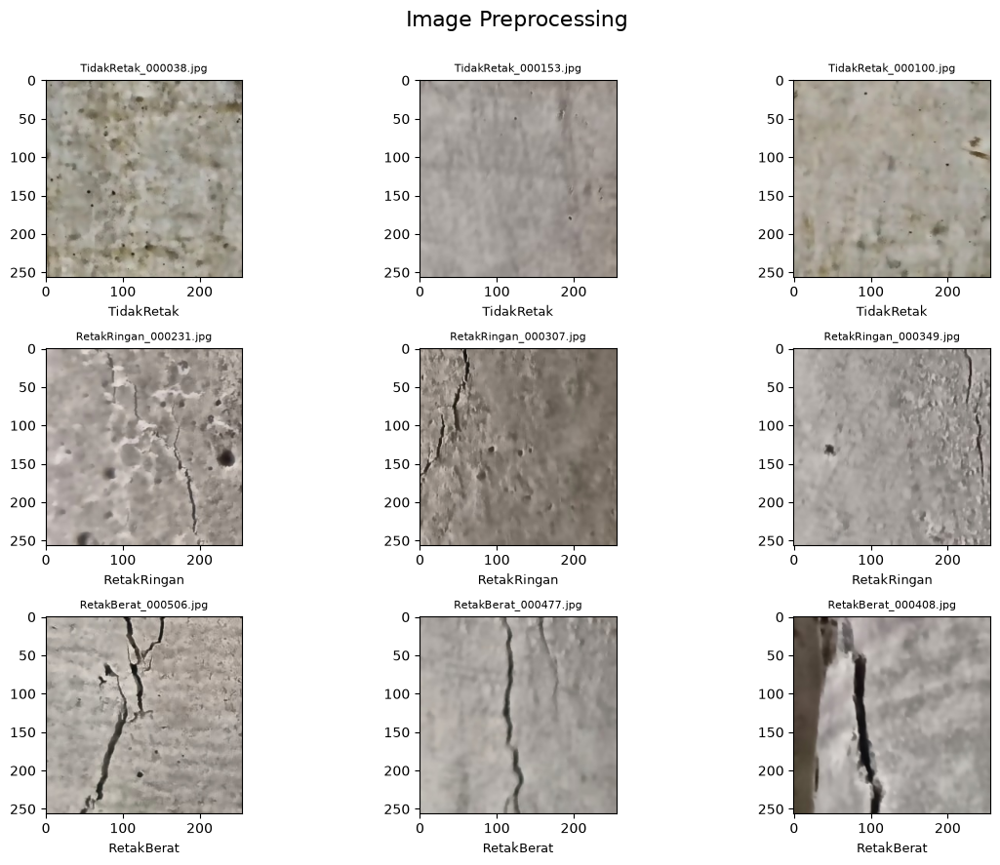

In [10]:
import os
import cv2
import matplotlib.pyplot as plt
import random

# Lokasi folder hasil preprocessing
preprocessed_dir = "Tanggul/eksperimen/dataset/preprocessed"

# Daftar kelas
classes = ["TidakRetak", "RetakRingan", "RetakBerat"]
num_images = 3  # jumlah gambar per kelas

# Buat grid: baris = kelas, kolom = jumlah gambar
fig, axes = plt.subplots(len(classes), num_images, figsize=(12, 9))
fig.suptitle("Image Preprocessing", fontsize=16)

for row, cls in enumerate(classes):
    class_dir = os.path.join(preprocessed_dir, cls)
    if not os.path.exists(class_dir):
        print(f"Folder tidak ditemukan: {class_dir}")
        continue

    # Ambil semua file gambar valid
    image_files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if len(image_files) == 0:
        print(f"Tidak ada gambar di kelas: {cls}")
        continue

    # Pilih acak sejumlah num_images
    selected_files = random.sample(image_files, min(num_images, len(image_files)))

    for col, fname in enumerate(selected_files):
        img_path = os.path.join(class_dir, fname)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # konversi ke RGB

        ax = axes[row, col]
        ax.imshow(img)
        ax.set_title(fname, fontsize=8)
        ax.set_xlabel(cls, fontsize=9)
        ax.axis("on")

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

PRA-PEMROSESAN DATA

In [13]:
import os
import json
from PIL import Image
from tqdm import tqdm

# Lokasi folder hasil preprocessing
IMG_DIR = "Tanggul/eksperimen/dataset/preprocessed"

# Lokasi file output JSON
OUT_JSON = "Tanggul/eksperimen/dataset/annotations/preprocessed.json"

# Definisi kategori (3 kelas)
CLASSES = {
    "TidakRetak": 0,
    "RetakRingan": 1,
    "RetakBerat": 2
}

Inisialisasi struktur COCO

In [14]:
images = []
annotations = []
img_id = 1
ann_id = 1

Loop per kelas & buat entri image + annotation

In [15]:
for cls_name, cls_id in CLASSES.items():
    class_dir = os.path.join(IMG_DIR, cls_name)
    if not os.path.isdir(class_dir):
        print(f"Folder kelas tidak ditemukan: {class_dir}")
        continue

    for file_name in tqdm(os.listdir(class_dir), desc=f"Proses {cls_name}"):
        if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(class_dir, file_name)
        try:
            with Image.open(path) as im:
                w, h = im.size
        except:
            continue

        # Tambahkan entry image
        images.append({
            "id": img_id,
            "file_name": os.path.join(cls_name, file_name),  # path relatif
            "width": w,
            "height": h
        })

        # Dummy annotation: bbox full image
        annotations.append({
            "id": ann_id,
            "image_id": img_id,
            "category_id": cls_id,
            "bbox": [0, 0, w, h],
            "segmentation": [[0, 0, w, 0, w, h, 0, h]],
            "area": w * h,
            "iscrowd": 0
        })

        img_id += 1
        ann_id += 1

Proses RetakBerat: 100%|██████████| 200/200 [00:00<00:00, 1997.09it/s]


Gabungkan ke format COCO & simpan JSON

In [16]:
coco_format = {
    "images": images,
    "annotations": annotations,
    "categories": [
        {"id": 0, "name": "TidakRetak", "supercategory": "crack"},
        {"id": 1, "name": "RetakRingan", "supercategory": "crack"},
        {"id": 2, "name": "RetakBerat", "supercategory": "crack"}
    ]
}

os.makedirs(os.path.dirname(OUT_JSON), exist_ok=True)
with open(OUT_JSON, "w") as f:
    json.dump(coco_format, f, indent=2)

print(f"File COCO berhasil dibuat: {OUT_JSON}")
print(f"Total images: {len(images)}, Total annotations: {len(annotations)}")

File COCO berhasil dibuat: Tanggul/eksperimen/dataset/annotations/preprocessed.json
Total images: 600, Total annotations: 600


Hasil JSON

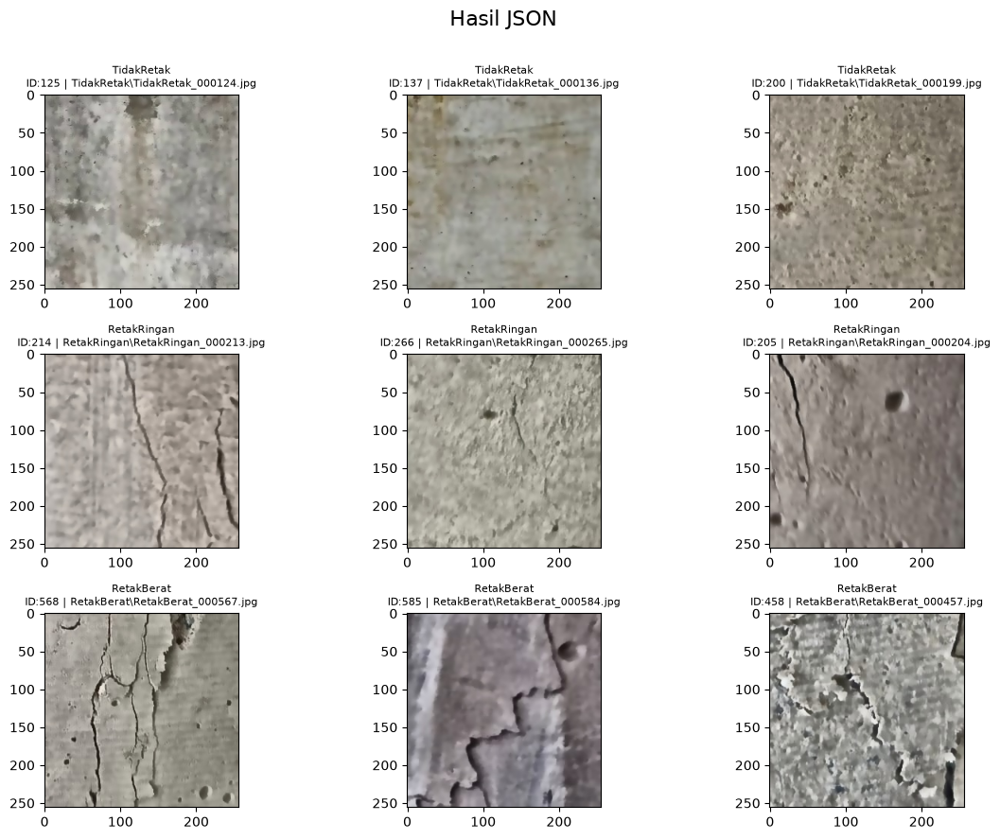

In [17]:
import json
import os
import random
import cv2
import matplotlib.pyplot as plt

# Baca file JSON
with open(OUT_JSON, "r") as f:
    coco_data = json.load(f)

# Buat mapping kategori
id_to_class = {cat["id"]: cat["name"] for cat in coco_data["categories"]}

# Buat mapping image_id -> file_name
id_to_file = {img["id"]: img["file_name"] for img in coco_data["images"]}

# Ambil gambar per kelas
num_samples = 3
fig, axes = plt.subplots(len(id_to_class), num_samples, figsize=(12, 9))
fig.suptitle("Hasil JSON", fontsize=16)

for row, (cat_id, cat_name) in enumerate(id_to_class.items()):
    # Cari semua image_id yang punya category_id 
    img_ids = [ann["image_id"] for ann in coco_data["annotations"] if ann["category_id"] == cat_id]
    img_ids = list(set(img_ids))  # unik

    if len(img_ids) == 0:
        continue

    # Pilih acak
    selected_ids = random.sample(img_ids, min(num_samples, len(img_ids)))

    for col, img_id in enumerate(selected_ids):
        fname = id_to_file[img_id]
        img_path = os.path.join(IMG_DIR, fname)

        img = cv2.imread(img_path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax = axes[row, col]
        ax.imshow(img)
        ax.set_title(f"{cat_name}\nID:{img_id} | {fname}", fontsize=8)
        ax.axis("on")

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()

LABEL SEGMENTATION MASK ("Retak Berat, Retak Ringan, Tidak Retak")

Hasil Label (Tidak Retak)

In [19]:
import os, json, random, cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

json_choice = "test"  

BASE_DIR = r"Tanggul/eksperimen/dataset/label_segmentation_mask"
IMAGE_DIR = os.path.join(BASE_DIR, json_choice)
ANNOT_PATH = os.path.join(IMAGE_DIR, f"{json_choice}_annotations.coco.json")

COLOR_RGB_YELLOW = (255, 255, 100) 

try:
    font = ImageFont.truetype("times.ttf", 16)
except:
    font = ImageFont.load_default()

Load JSON dan Filter Gambar “Tidak Retak”

In [20]:
# Load file COCO JSON
with open(ANNOT_PATH, "r") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = coco["categories"]

# Cari ID kategori "Tidak Retak"
tidak_retak_ids = [c["id"] for c in categories if "tidak" in c["name"].lower()]
if not tidak_retak_ids:
    raise ValueError("Kategori 'Tidak Retak' tidak ditemukan di file anotasi.")

# Filter gambar yang punya anotasi kategori "Tidak Retak"
valid_imgs = []
for img_info in images:
    img_id = img_info["id"]
    annots = [a for a in annotations if a["image_id"] == img_id and a["category_id"] in tidak_retak_ids]
    if annots:
        valid_imgs.append((img_info, annots))

# Pilih gambar acak
sample_imgs = random.sample(valid_imgs, min(9, len(valid_imgs)))

Visualisasi Segmentasi “Tidak Retak”

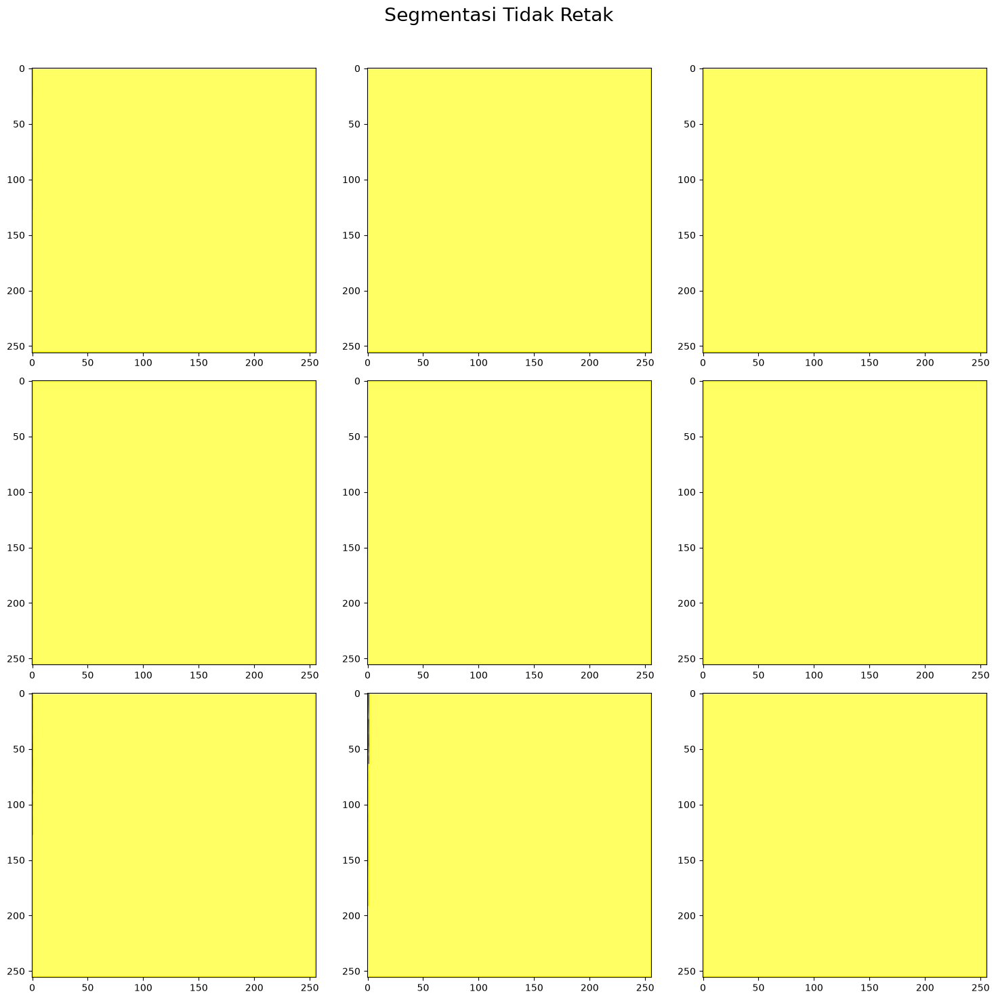

In [21]:
plt.figure(figsize=(15,15))
for i, (img_info, annots) in enumerate(sample_imgs, 1):
    fname = img_info["file_name"]
    img_path = os.path.join(IMAGE_DIR, fname)
    img = cv2.imread(img_path)
    if img is None:
        continue

    img_resized = cv2.resize(img, (256, 256))
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(img_rgb).convert("RGBA")
    overlay = Image.new("RGBA", pil_img.size, (0,0,0,0))
    draw = ImageDraw.Draw(overlay)

    scale_x = 256 / img_info["width"]
    scale_y = 256 / img_info["height"]

    for ann in annots:
        if "segmentation" in ann and isinstance(ann["segmentation"], list):
            for seg in ann["segmentation"]:
                poly = [(int(seg[j] * scale_x), int(seg[j+1] * scale_y)) for j in range(0, len(seg), 2)]
                draw.polygon(poly, outline=(255,255,0,255), fill=COLOR_RGB_YELLOW)

    combined = Image.alpha_composite(pil_img, overlay)

    # Tampilkan
    plt.subplot(3, 3, i)
    plt.imshow(combined)
    plt.axis("on")

plt.suptitle("Segmentasi Tidak Retak", fontsize=20)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show("on")

Hasil Label (Retak Ringan)

In [22]:
json_choice = "train" 

# Path ke folder JSON dan gambar
BASE_DIR = r"Tanggul/eksperimen/dataset/label_segmentation_mask"
IMAGE_DIR = os.path.join(BASE_DIR, json_choice)
ANNOT_PATH = os.path.join(IMAGE_DIR, f"{json_choice}_annotations.coco.json")

# Warna segmentasi 
COLOR_RGB_RED = (255, 0, 0, 100)

# Load font
try:
    font = ImageFont.truetype("times.ttf", 16)
except:
    font = ImageFont.load_default()

Load JSON dan Filter Gambar “Retak Ringan”

In [23]:
# Load file COCO JSON
with open(ANNOT_PATH, "r") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = coco["categories"]

# Cari ID kategori "Retak Ringan"
retak_ringan_ids = [c["id"] for c in categories if "ringan" in c["name"].lower()]
if not retak_ringan_ids:
    raise ValueError("Kategori 'Retak Ringan' tidak ditemukan di file anotasi.")

# Filter gambar yang punya anotasi kategori "Retak Ringan"
valid_imgs = []
for img_info in images:
    img_id = img_info["id"]
    annots = [a for a in annotations if a["image_id"] == img_id and a["category_id"] in retak_ringan_ids]
    if annots:
        valid_imgs.append((img_info, annots))

# Pilih gambar acak
sample_imgs = random.sample(valid_imgs, min(9, len(valid_imgs)))

Visualisasi Segmentasi “Retak Ringan”

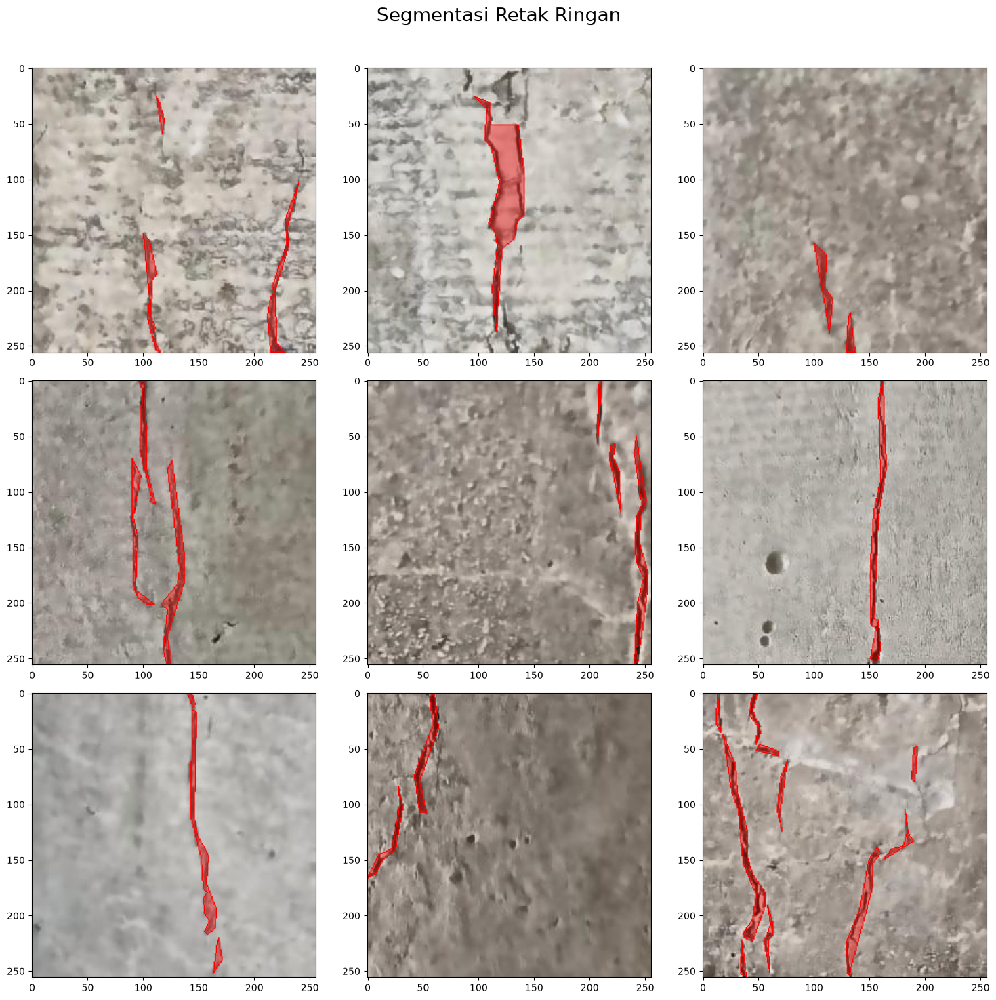

In [24]:
plt.figure(figsize=(15,15))
for i, (img_info, annots) in enumerate(sample_imgs, 1):
    fname = img_info["file_name"]
    img_path = os.path.join(IMAGE_DIR, fname)
    img = cv2.imread(img_path)
    if img is None:
        continue

    img_resized = cv2.resize(img, (256, 256))
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(img_rgb).convert("RGBA")
    overlay = Image.new("RGBA", pil_img.size, (0,0,0,0))
    draw = ImageDraw.Draw(overlay)

    scale_x = 256 / img_info["width"]
    scale_y = 256 / img_info["height"]

    for ann in annots:
        if "segmentation" in ann and isinstance(ann["segmentation"], list):
            for seg in ann["segmentation"]:
                poly = [(int(seg[j] * scale_x), int(seg[j+1] * scale_y)) for j in range(0, len(seg), 2)]
                draw.polygon(poly, outline=(255,0,0,255), fill=COLOR_RGB_RED)

    # Gabungkan overlay
    combined = Image.alpha_composite(pil_img, overlay)

    # Tampilkan
    plt.subplot(3, 3, i)
    plt.imshow(combined)
    plt.axis("on")

plt.suptitle("Segmentasi Retak Ringan", fontsize=20)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show("on")

Hasil Label (Retak Berat)

In [25]:
json_choice = "train" 

BASE_DIR = r"Tanggul/eksperimen/dataset/label_segmentation_mask"
IMAGE_DIR = os.path.join(BASE_DIR, json_choice)
ANNOT_PATH = os.path.join(IMAGE_DIR, f"{json_choice}_annotations.coco.json")

COLOR_RGB_PURPLE = (128, 0, 128, 100)

# Load font
try:
    font = ImageFont.truetype("times.ttf", 16)
except:
    font = ImageFont.load_default()

Load JSON dan Filter Gambar “Retak Berat”

In [26]:
with open(ANNOT_PATH, "r") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = coco["categories"]

# Cari ID kategori "Retak Berat"
retak_berat_ids = [c["id"] for c in categories if "berat" in c["name"].lower()]
if not retak_berat_ids:
    raise ValueError("Kategori 'Retak Berat' tidak ditemukan di file anotasi.")

# Filter gambar yang punya anotasi kategori "Retak Berat"
valid_imgs = []
for img_info in images:
    img_id = img_info["id"]
    annots = [a for a in annotations if a["image_id"] == img_id and a["category_id"] in retak_berat_ids]
    if annots:
        valid_imgs.append((img_info, annots))

# Pilih gambar acak
sample_imgs = random.sample(valid_imgs, min(9, len(valid_imgs)))

Visualisasi Segmentasi “Retak Berat”

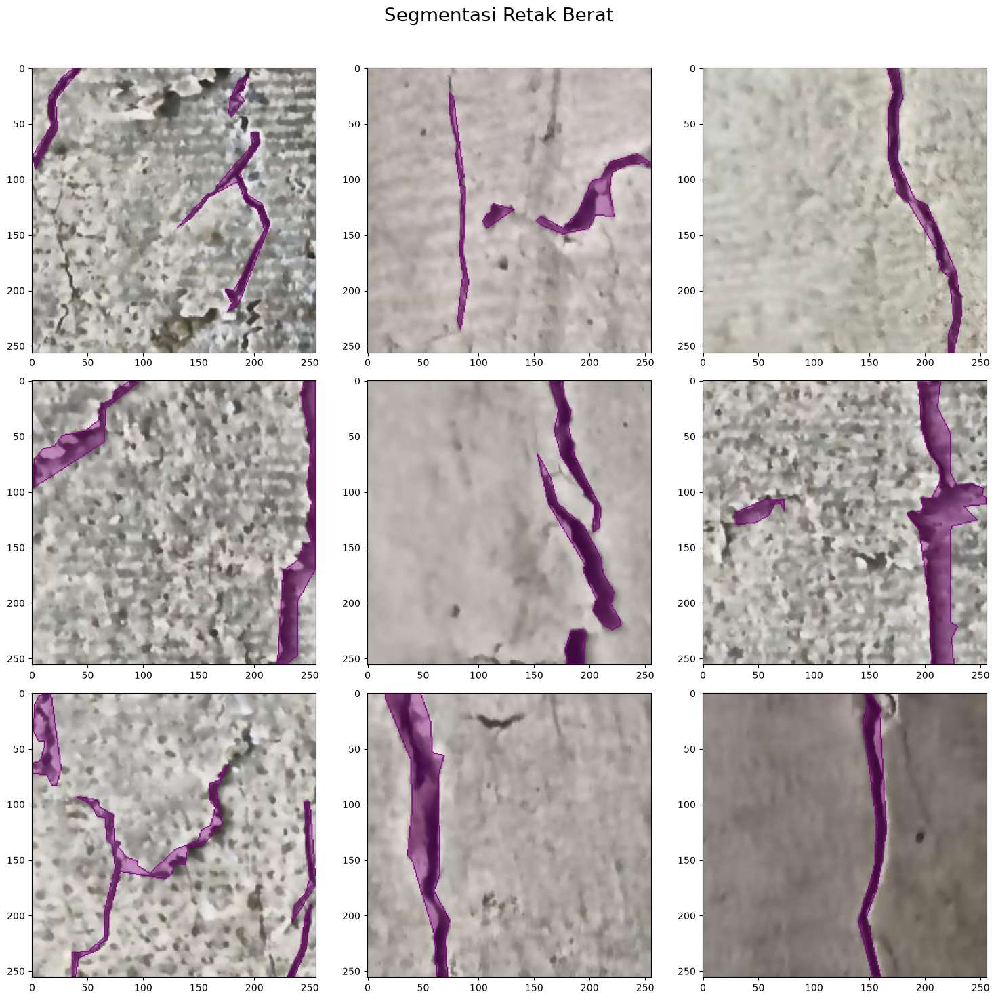

In [27]:
plt.figure(figsize=(15,15))
for i, (img_info, annots) in enumerate(sample_imgs, 1):
    fname = img_info["file_name"]
    img_path = os.path.join(IMAGE_DIR, fname)
    img = cv2.imread(img_path)
    if img is None:
        continue

    # Resize ke 256x256
    img_resized = cv2.resize(img, (256, 256))
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(img_rgb).convert("RGBA")
    overlay = Image.new("RGBA", pil_img.size, (0,0,0,0))
    draw = ImageDraw.Draw(overlay)

    # Skala polygon dari ukuran asli ke 256x256
    scale_x = 256 / img_info["width"]
    scale_y = 256 / img_info["height"]

    for ann in annots:
        if "segmentation" in ann and isinstance(ann["segmentation"], list):
            for seg in ann["segmentation"]:
                poly = [(int(seg[j] * scale_x), int(seg[j+1] * scale_y)) for j in range(0, len(seg), 2)]
                draw.polygon(poly, outline=(128,0,128,255), fill=COLOR_RGB_PURPLE)

    # Gabungkan overlay dengan gambar asli
    combined = Image.alpha_composite(pil_img, overlay)

    # Tampilkan
    plt.subplot(3, 3, i)
    plt.imshow(combined)
    plt.axis("on")

plt.suptitle("Segmentasi Retak Berat", fontsize=20)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show("on")

Split Dataset Segmentation_Mask

In [28]:
base_path_seg = "Tanggul/eksperimen/dataset/label_segmentation_mask"
splits_seg = ["train", "valid", "test"]
total_seg = 0

for split in splits_seg:
    annot_file = os.path.join(base_path_seg, split, f"{split}_annotations.coco.json")
    
    try:
        
        with open(annot_file, 'r') as f:
            coco_data = json.load(f)
        
       
        images_list = coco_data.get("images", [])
        
        count = len(images_list)
        total_seg += count
        
        print(f"Memuat {count} gambar dari split '{split}'")
        
    except FileNotFoundError:
        print(f"File anotasi tidak ditemukan untuk split '{split}' {annot_file}")
    except Exception as e:
        print(f"ERROR: Gagal membaca file JSON untuk split '{split}': {e}")

print(f"Total gambar (Segmentation): {total_seg}")

Memuat 420 gambar dari split 'train'
Memuat 90 gambar dari split 'valid'
Memuat 90 gambar dari split 'test'
Total gambar (Segmentation): 600


Augmentasi Segmentation Mask

Import Library dan Konfigurasi

In [29]:
import os
import cv2
import numpy as np
import json
import glob
from tqdm import tqdm
import shutil

# KONFIGURASI
INPUT_BASE_DIR = "Tanggul/eksperimen/dataset/label_segmentation_mask"
OUTPUT_BASE_DIR = "Tanggul/eksperimen/dataset/label_segmentation_mask_with_masks"

print("MEMPROSES COCO JSON UNTUK MEMBUAT MASK")

# Buat folder output
os.makedirs(OUTPUT_BASE_DIR, exist_ok=True)

def process_coco_json():
    for split in ["train", "valid", "test"]:
        print(f"\nMemproses {split}")
        
        split_input_dir = os.path.join(INPUT_BASE_DIR, split)
        split_output_dir = os.path.join(OUTPUT_BASE_DIR, split)
        
        # Buat folder output
        os.makedirs(split_output_dir, exist_ok=True)
        
        # Cari file JSON
        json_files = glob.glob(os.path.join(split_input_dir, "*.json"))
        if not json_files:
            print(f"  Tidak ada file JSON ditemukan di {split}")
            continue
            
        json_file = json_files[0]  # Ambil file JSON pertama
        print(f"  Memproses: {os.path.basename(json_file)}")
        
        # Baca file JSON
        try:
            with open(json_file, 'r') as f:
                coco_data = json.load(f)
        except Exception as e:
            print(f"  Error membaca JSON: {e}")
            continue
        
        # Proses setiap gambar
        images_processed = 0
        masks_created = 0
        
        for image_info in tqdm(coco_data.get('images', []), desc=f"  {split}"):
            image_filename = image_info['file_name']
            image_id = image_info['id']
            image_width = image_info['width']
            image_height = image_info['height']
            
            # Path gambar asli
            image_input_path = os.path.join(split_input_dir, image_filename)
            
            if not os.path.exists(image_input_path):
                print(f"    Gambar tidak ditemukan: {image_filename}")
                continue
            
            # Salin gambar ke output
            image_output_path = os.path.join(split_output_dir, image_filename)
            shutil.copy(image_input_path, image_output_path)
            images_processed += 1
            
            # Buat mask kosong
            mask = np.zeros((image_height, image_width), dtype=np.uint8)
            
            # Cari annotations untuk gambar ini
            annotations = [ann for ann in coco_data.get('annotations', []) if ann['image_id'] == image_id]
            
            if annotations:
                # Proses setiap annotation
                for ann in annotations:
                    category_id = ann['category_id']
                    segmentation = ann['segmentation']
                    
                    # Buat mask dari segmentation
                    if segmentation:
                        # Untuk polygon segmentation
                        for polygon in segmentation:
                            points = np.array(polygon, dtype=np.int32).reshape(-1, 2)
                            cv2.fillPoly(mask, [points], color=category_id)
            
            # Simpan mask
            mask_filename = os.path.splitext(image_filename)[0] + ".png"
            mask_output_path = os.path.join(split_output_dir, mask_filename)
            cv2.imwrite(mask_output_path, mask)
            masks_created += 1
        
        print(f"  Selesai: {images_processed} gambar diproses, {masks_created} mask dibuat")

# Jalankan proses
process_coco_json()

print(f"\nPROSES SELESAI")
print(f"Output disimpan di: {OUTPUT_BASE_DIR}")

MEMPROSES COCO JSON UNTUK MEMBUAT MASK

Memproses train
  Memproses: train_annotations.coco.json


  train: 100%|██████████| 420/420 [00:03<00:00, 108.41it/s]


  Selesai: 420 gambar diproses, 420 mask dibuat

Memproses valid
  Memproses: valid_annotations.coco.json


  valid: 100%|██████████| 90/90 [00:00<00:00, 179.27it/s]


  Selesai: 90 gambar diproses, 90 mask dibuat

Memproses test
  Memproses: test_annotations.coco.json


  test: 100%|██████████| 90/90 [00:00<00:00, 106.91it/s]

  Selesai: 90 gambar diproses, 90 mask dibuat

PROSES SELESAI
Output disimpan di: Tanggul/eksperimen/dataset/label_segmentation_mask_with_masks


Verifikasi Hasil

In [30]:
print("VERIFIKASI HASIL MASK")

for split in ["train", "valid", "test"]:
    split_dir = os.path.join(OUTPUT_BASE_DIR, split)
    
    if os.path.exists(split_dir):
        jpg_files = glob.glob(os.path.join(split_dir, "*.jpg"))
        png_files = glob.glob(os.path.join(split_dir, "*.png"))
        
        print(f"\n{split}:")
        print(f"  JPG files: {len(jpg_files)}")
        print(f"  PNG files: {len(png_files)}")
        
        # Cek pasangan
        valid_pairs = 0
        for jpg_file in jpg_files[:5]:  # Cek 5 pertama
            base_name = os.path.splitext(os.path.basename(jpg_file))[0]
            mask_file = os.path.join(split_dir, base_name + ".png")
            if os.path.exists(mask_file):
                valid_pairs += 1
        
        print(f"  Pasangan valid: {valid_pairs}/{min(5, len(jpg_files))}")
        
        # Tampilkan contoh
        if jpg_files:
            sample_jpg = jpg_files[0]
            sample_png = os.path.splitext(sample_jpg)[0] + ".png"
            print(f"  Contoh: {os.path.basename(sample_jpg)} -> {os.path.basename(sample_png)}")
            
            # Cek ukuran mask
            if os.path.exists(sample_png):
                mask = cv2.imread(sample_png, cv2.IMREAD_GRAYSCALE)
                unique_values = np.unique(mask)
                print(f"  Nilai unik dalam mask: {unique_values}")
    else:
        print(f"\n{split}: folder tidak ada")

VERIFIKASI HASIL MASK

train:
  JPG files: 420
  PNG files: 420
  Pasangan valid: 5/5
  Contoh: RetakBerat_000401_jpg.rf.0b8c240923300ef36a67cfa2344426dc.jpg -> RetakBerat_000401_jpg.rf.0b8c240923300ef36a67cfa2344426dc.png
  Nilai unik dalam mask: [0 1]

valid:
  JPG files: 90
  PNG files: 90
  Pasangan valid: 5/5
  Contoh: RetakBerat_000400_jpg.rf.1b35f9f58086ae70fa465095e711f881.jpg -> RetakBerat_000400_jpg.rf.1b35f9f58086ae70fa465095e711f881.png
  Nilai unik dalam mask: [0 1]

test:
  JPG files: 90
  PNG files: 90
  Pasangan valid: 5/5
  Contoh: RetakBerat_000403_jpg.rf.bcb84c8e693a991a7805539f15b13eeb.jpg -> RetakBerat_000403_jpg.rf.bcb84c8e693a991a7805539f15b13eeb.png
  Nilai unik dalam mask: [0 1]


Update Konfigurasi untuk Augmentasi

In [31]:
print("UPDATE KONFIGURASI AUGMENTASI")

UPDATED_INPUT_BASE_DIR = "Tanggul/eksperimen/dataset/label_segmentation_mask_with_masks"
UPDATED_OUTPUT_BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"

print(f"Input directory: {UPDATED_INPUT_BASE_DIR}")
print(f"Output directory: {UPDATED_OUTPUT_BASE_DIR}")

# Simpan konfigurasi untuk digunakan
config = {
    "INPUT_BASE_DIR": UPDATED_INPUT_BASE_DIR,
    "OUTPUT_BASE_DIR": UPDATED_OUTPUT_BASE_DIR,
    "SPLITS_TO_AUGMENT": ["train", "valid"],
    "SPLITS_TO_COPY": ["test"],
    "TARGET_COUNT": 3000,
    "TRAIN_VAL_SPLIT_RATIO": 0.7
}

print("\nKonfigurasi siap untuk augmentasi")

UPDATE KONFIGURASI AUGMENTASI
Input directory: Tanggul/eksperimen/dataset/label_segmentation_mask_with_masks
Output directory: Tanggul/eksperimen/dataset/augmentasi_mask

Konfigurasi siap untuk augmentasi


Fungsi untuk Menemukan Gambar dan Mask

In [32]:
def find_images_and_masks(split_dir):

    # Cari semua file gambar
    image_files = glob.glob(os.path.join(split_dir, "*.jpg"))
    
    images = []
    masks = []
    
    print(f"  Ditemukan {len(image_files)} file gambar")
    
    for img_path in image_files:
        base_name = os.path.basename(img_path)
        name_without_ext = os.path.splitext(base_name)[0]
        
        # Cari file mask dengan nama yang sama + .png
        mask_path = os.path.join(split_dir, name_without_ext + ".png")
        
        if os.path.exists(mask_path):
            images.append(img_path)
            masks.append(mask_path)
        else:
            print(f"  WARNING: Mask tidak ditemukan untuk {base_name}")
    
    print(f"  Ditemukan {len(images)} pasangan gambar-mask yang valid")
    return list(zip(images, masks))

# Test fungsi untuk setiap split
print(f"\nTEST PENCARIAN GAMBAR DAN MASK")
for split in ["train", "valid"]:
    split_dir = os.path.join(UPDATED_INPUT_BASE_DIR, split)
    if os.path.exists(split_dir):
        print(f"\nMencari di {split}:")
        pairs = find_images_and_masks(split_dir)
        if pairs:
            print(f"  Contoh pasangan:")
            for i, (img_path, mask_path) in enumerate(pairs[:3]):
                print(f"    {os.path.basename(img_path)} -> {os.path.basename(mask_path)}")


TEST PENCARIAN GAMBAR DAN MASK

Mencari di train:
  Ditemukan 420 file gambar
  Ditemukan 420 pasangan gambar-mask yang valid
  Contoh pasangan:
    RetakBerat_000401_jpg.rf.0b8c240923300ef36a67cfa2344426dc.jpg -> RetakBerat_000401_jpg.rf.0b8c240923300ef36a67cfa2344426dc.png
    RetakBerat_000402_jpg.rf.bf1340043e19d44f9ada50e434041d0b.jpg -> RetakBerat_000402_jpg.rf.bf1340043e19d44f9ada50e434041d0b.png
    RetakBerat_000404_jpg.rf.4a38b6a85c00673e83d4a27333d7bfdf.jpg -> RetakBerat_000404_jpg.rf.4a38b6a85c00673e83d4a27333d7bfdf.png

Mencari di valid:
  Ditemukan 90 file gambar
  Ditemukan 90 pasangan gambar-mask yang valid
  Contoh pasangan:
    RetakBerat_000400_jpg.rf.1b35f9f58086ae70fa465095e711f881.jpg -> RetakBerat_000400_jpg.rf.1b35f9f58086ae70fa465095e711f881.png
    RetakBerat_000406_jpg.rf.65ee7379d80082d8b5ed2702ca43ade1.jpg -> RetakBerat_000406_jpg.rf.65ee7379d80082d8b5ed2702ca43ade1.png
    RetakBerat_000407_jpg.rf.44175c1c273dd41e890e9380ae021051.jpg -> RetakBerat_000407_

Pipeline Augmentasi

In [34]:
import cv2
import albumentations as A

# PIPELINE AUGMENTASI SOTA
sota_seg_pipeline = A.Compose([
    # Geometri Dasar
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),

    # Geometri SOTA
    A.OneOf([
        A.ElasticTransform(p=0.7, alpha=120, sigma=120 * 0.05,
                          border_mode=cv2.BORDER_CONSTANT, 
                          value=0, 
                          mask_value=0, 
                          interpolation=cv2.INTER_LINEAR, 
                          mask_interpolation=cv2.INTER_NEAREST),
        
        A.GridDistortion(p=0.7, border_mode=cv2.BORDER_CONSTANT, 
                         value=0, 
                         mask_value=0, 
                         interpolation=cv2.INTER_LINEAR, 
                         mask_interpolation=cv2.INTER_NEAREST),
        
        A.ShiftScaleRotate(p=0.8, shift_limit=0.1, scale_limit=0.1, rotate_limit=45,
                          border_mode=cv2.BORDER_CONSTANT, 
                          value=0,
                          mask_value=0, 
                          interpolation=cv2.INTER_LINEAR, 
                          mask_interpolation=cv2.INTER_NEAREST) 
    ], p=0.9), 

    # Fokus pada Kontras & Kejelasan
    A.OneOf([
        A.CLAHE(clip_limit=4.0, p=0.7),
        A.RandomBrightnessContrast(p=0.8),
        A.RandomGamma(p=0.7),
    ], p=0.9),

    # Efek Noise & Blur
    A.OneOf([
        A.GaussNoise(p=0.5),
        A.Blur(blur_limit=3, p=0.5),
    ], p=0.5),

    # Teknik Occlusion Cutout
    A.CoarseDropout(
        max_holes=10, 
        max_height=40, 
        max_width=40,
        min_holes=5, 
        min_height=20, 
        min_width=20,
        fill_value=0, 
        mask_fill_value=0,
        p=0.7)
])

print("Pipeline augmentasi didefinisikan")

Pipeline augmentasi didefinisikan


C:\Users\Dwi-Metcha\AppData\Local\Temp\ipykernel_9268\3388321439.py:12: UserWarning: Argument(s) 'value, mask_value' are not valid for transform ElasticTransform
  A.ElasticTransform(p=0.7, alpha=120, sigma=120 * 0.05,
C:\Users\Dwi-Metcha\AppData\Local\Temp\ipykernel_9268\3388321439.py:19: UserWarning: Argument(s) 'value, mask_value' are not valid for transform GridDistortion
  A.GridDistortion(p=0.7, border_mode=cv2.BORDER_CONSTANT,
C:\Users\Dwi-Metcha\AppData\Local\Temp\ipykernel_9268\3388321439.py:25: UserWarning: Argument(s) 'value, mask_value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(p=0.8, shift_limit=0.1, scale_limit=0.1, rotate_limit=45,
C:\Users\Dwi-Metcha\AppData\Local\Temp\ipykernel_9268\3388321439.py:47: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value, mask_fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(


Fungsi Utama Augmentasi

In [35]:
def process_segmentation_dataset():
    INPUT_BASE_DIR = "Tanggul/eksperimen/dataset/label_segmentation_mask_with_masks"
    OUTPUT_BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    
    SPLITS_TO_AUGMENT = ["train", "valid"]
    SPLITS_TO_COPY = ["test"]
    TARGET_COUNT = 3000
    TRAIN_VAL_SPLIT_RATIO = 0.7
    
    # Salin dataset test tanpa augmentasi
    for split in SPLITS_TO_COPY:
        input_split_dir = os.path.join(INPUT_BASE_DIR, split)
        output_split_dir = os.path.join(OUTPUT_BASE_DIR, split)
        
        if os.path.exists(output_split_dir):
            print(f"Menghapus folder '{split}' lama...")
            shutil.rmtree(output_split_dir)
            
        if os.path.exists(input_split_dir):
            # Cari semua gambar dan mask untuk test
            test_pairs = find_images_and_masks(input_split_dir)
            if test_pairs:
                # Buat folder output
                os.makedirs(output_split_dir, exist_ok=True)
                
                # Salin gambar dan mask
                for img_path, mask_path in test_pairs:
                    img_filename = os.path.basename(img_path)
                    mask_filename = os.path.basename(mask_path)
                    
                    shutil.copy(img_path, os.path.join(output_split_dir, img_filename))
                    shutil.copy(mask_path, os.path.join(output_split_dir, mask_filename))
                
                print(f"Berhasil menyalin {len(test_pairs)} pasangan gambar-mask untuk test")
            else:
                print(f"Tidak ada gambar ditemukan untuk test di {input_split_dir}")
        else:
            print(f"Folder test tidak ditemukan di {input_split_dir}, lanjut tanpa test")
    
    # Augmentasi untuk train dan valid
    all_augmented_data = {"train": [], "valid": []}
    original_counts = {}
    
    for split in SPLITS_TO_AUGMENT:
        print(f"\nMEMULAI AUGMENTASI UNTUK '{split.upper()}'")
        
        # Cari semua gambar dan mask
        input_split_dir = os.path.join(INPUT_BASE_DIR, split)
        image_mask_pairs = find_images_and_masks(input_split_dir)

        if not image_mask_pairs:
            print(f"Tidak ada gambar ditemukan di {input_split_dir}")
            print(f"Augmentasi '{split}' dibatalkan.")
            continue

        original_counts[split] = len(image_mask_pairs)
        print(f"Ditemukan {len(image_mask_pairs)} pasangan gambar-mask asli")
        print(f"Target augmentasi: {TARGET_COUNT} gambar")

        # Loop hingga target tercapai
        pbar = tqdm(total=TARGET_COUNT, desc=f"Augmentasi '{split}'")
        new_img_id = 1
        augmented_data = []
        
        while new_img_id <= TARGET_COUNT:
            # Pilih pasangan gambar-mask acak 
            img_path, mask_path = random.choice(image_mask_pairs)
            base_filename = os.path.basename(img_path)

            # Load gambar dan mask
            image = cv2.imread(img_path)
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            
            if image is None:
                continue
            if mask is None:
                continue
                
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Terapkan augmentasi
            try:
                transformed = sota_seg_pipeline(image=image, mask=mask)
                transformed_image = transformed['image']
                transformed_mask = transformed['mask']
            except Exception as e:
                continue 
                
            # Simpan informasi augmented data
            augmented_data.append({
                "image": transformed_image,
                "mask": transformed_mask,
                "original_name": base_filename,
                "new_id": new_img_id
            })
            
            new_img_id += 1
            pbar.update(1)
            
        pbar.close()
        all_augmented_data[split] = augmented_data
        print(f"Augmentasi {split} selesai: {len(augmented_data)} gambar")

    # Gabungkan dan split data
    print(f"\nMENGGABUNGKAN DAN MEMBAGI DATA")
    
    # Gabungkan semua data augmented
    all_data = []
    total_original = 0
    
    for split in SPLITS_TO_AUGMENT:
        all_data.extend(all_augmented_data[split])
        total_original += original_counts.get(split, 0)
    
    print(f"Total data asli: {total_original}")
    print(f"Total data augmented: {len(all_data)}")
    
    if not all_data:
        print("Tidak ada data yang diaugmentasi")
        return
    
    # Acak data
    random.shuffle(all_data)
    
    # Split data
    split_index = int(len(all_data) * TRAIN_VAL_SPLIT_RATIO)
    train_data = all_data[:split_index]
    val_data = all_data[split_index:]
    
    print(f"Split hasil:")
    print(f"  Train: {len(train_data)} gambar ({len(train_data)/len(all_data)*100:.1f}%)")
    print(f"  Valid: {len(val_data)} gambar ({len(val_data)/len(all_data)*100:.1f}%)")
    
    # Step 4: Simpan data train dan valid yang telah di-split
    for split_name, data in [("train", train_data), ("valid", val_data)]:
        print(f"\n=== MENYIMPAN DATA {split_name.upper()} ===")
        
        # Buat folder output
        output_split_dir = os.path.join(OUTPUT_BASE_DIR, split_name)
        os.makedirs(output_split_dir, exist_ok=True)
        
        # Simpan gambar dan mask
        for i, item in enumerate(tqdm(data, desc=f"Simpan {split_name}")):
            new_filename_base = f"{os.path.splitext(item['original_name'])[0]}_aug_{item['new_id']:06d}"
            
            # Simpan gambar
            new_filename_img = f"{new_filename_base}.jpg"
            output_img_path = os.path.join(output_split_dir, new_filename_img)
            cv2.imwrite(output_img_path, cv2.cvtColor(item['image'], cv2.COLOR_RGB2BGR))
            
            # Simpan mask
            new_filename_mask = f"{new_filename_base}.png"
            output_mask_path = os.path.join(output_split_dir, new_filename_mask)
            cv2.imwrite(output_mask_path, item['mask'])
    
    print("\nPROSES AUGMENTASI DAN SPLIT SELESAI")

# Jalankan augmentasi
process_segmentation_dataset()

Menghapus folder 'test' lama...
  Ditemukan 90 file gambar
  Ditemukan 90 pasangan gambar-mask yang valid
Berhasil menyalin 90 pasangan gambar-mask untuk test

MEMULAI AUGMENTASI UNTUK 'TRAIN'
  Ditemukan 420 file gambar
  Ditemukan 420 pasangan gambar-mask yang valid
Ditemukan 420 pasangan gambar-mask asli
Target augmentasi: 3000 gambar


Augmentasi 'train': 100%|██████████| 3000/3000 [00:42<00:00, 70.97it/s]


Augmentasi train selesai: 3000 gambar

MEMULAI AUGMENTASI UNTUK 'VALID'
  Ditemukan 90 file gambar
  Ditemukan 90 pasangan gambar-mask yang valid
Ditemukan 90 pasangan gambar-mask asli
Target augmentasi: 3000 gambar


Augmentasi 'valid': 100%|██████████| 3000/3000 [00:52<00:00, 56.69it/s]


Augmentasi valid selesai: 3000 gambar

MENGGABUNGKAN DAN MEMBAGI DATA
Total data asli: 510
Total data augmented: 6000
Split hasil:
  Train: 4200 gambar (70.0%)
  Valid: 1800 gambar (30.0%)

=== MENYIMPAN DATA TRAIN ===


Simpan train: 100%|██████████| 4200/4200 [00:59<00:00, 70.48it/s] 



=== MENYIMPAN DATA VALID ===


Simpan valid: 100%|██████████| 1800/1800 [00:25<00:00, 70.19it/s] 



PROSES AUGMENTASI DAN SPLIT SELESAI


Visualisasi Hasil Augmentasi


MEMULAI VISUALISASI HASIL AUGMENTASI

VISUALISASI HASIL AUGMENTASI

Visualisasi TRAIN


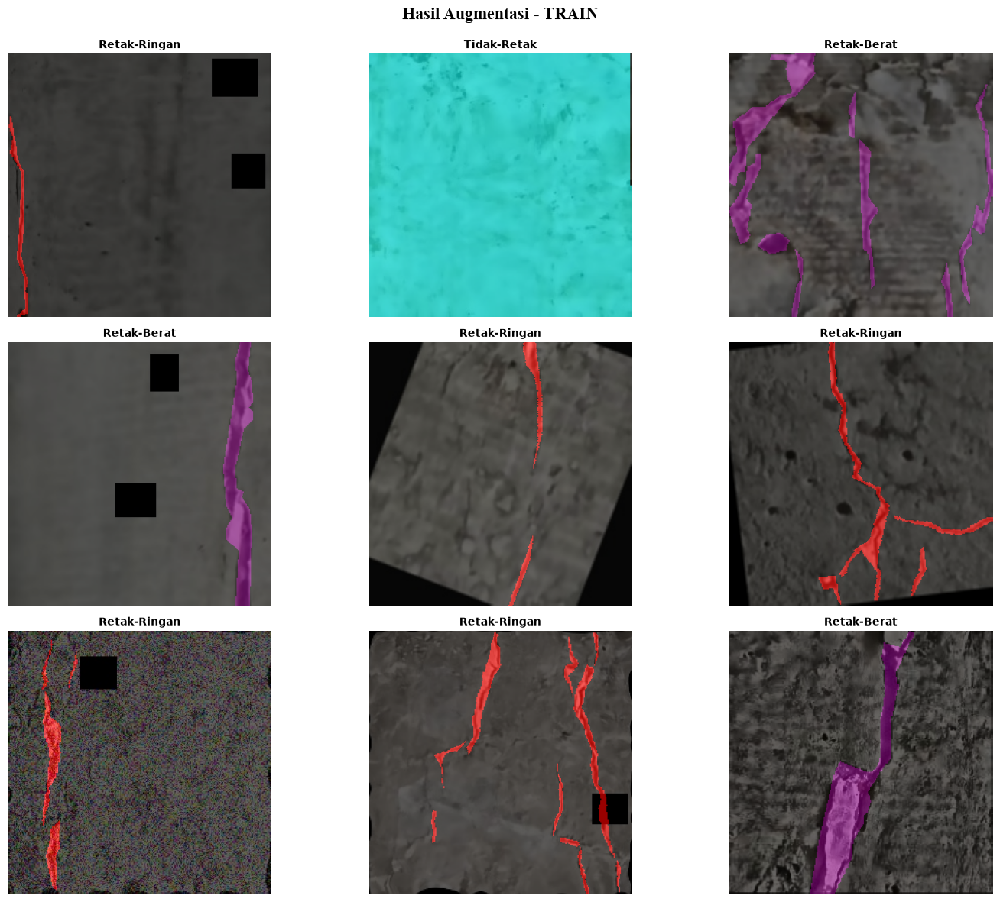


Statistik train:
  Total gambar augmentasi: 16693
  Distribusi class (dalam 100 sample):
    Retak-Berat: 100 (100.0%)
    Retak-Ringan: 0 (0.0%)
    Tidak-Retak: 0 (0.0%)

Visualisasi VALID


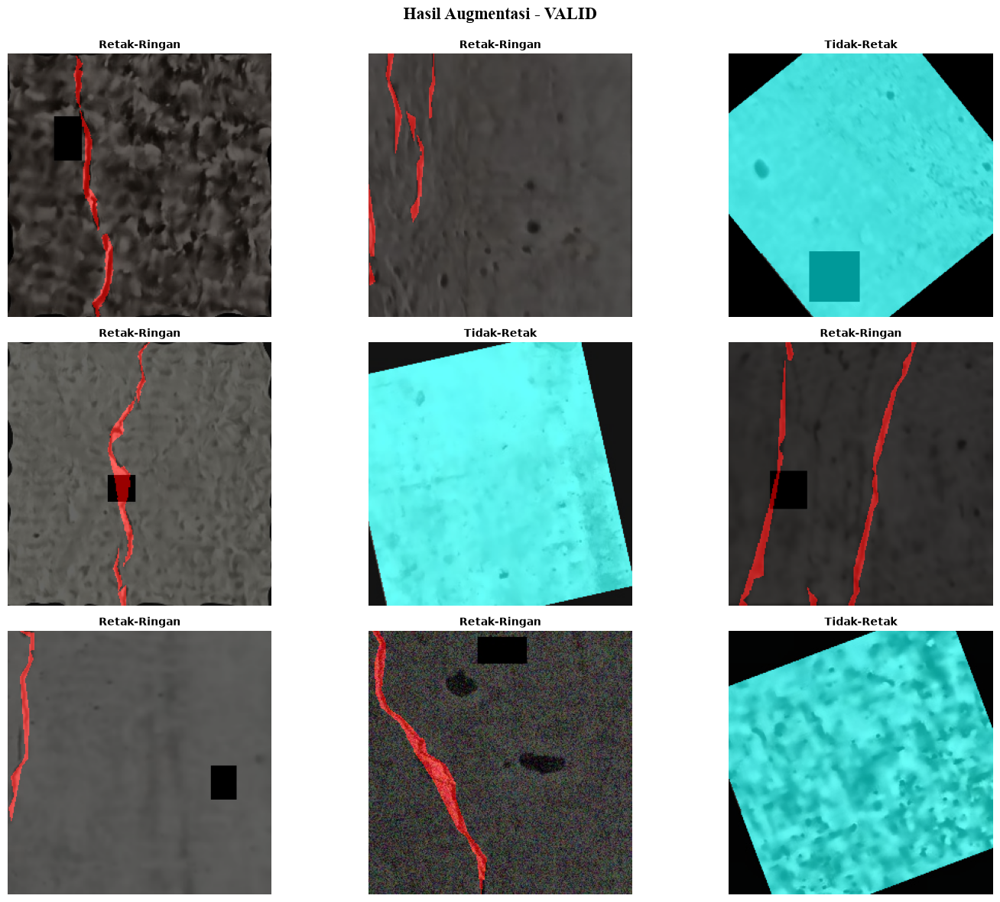


Statistik valid:
  Total gambar augmentasi: 7174
  Distribusi class (dalam 100 sample):
    Retak-Berat: 100 (100.0%)
    Retak-Ringan: 0 (0.0%)
    Tidak-Retak: 0 (0.0%)

PERBANDINGAN SEBELUM & SESUDAH AUGMENTASI


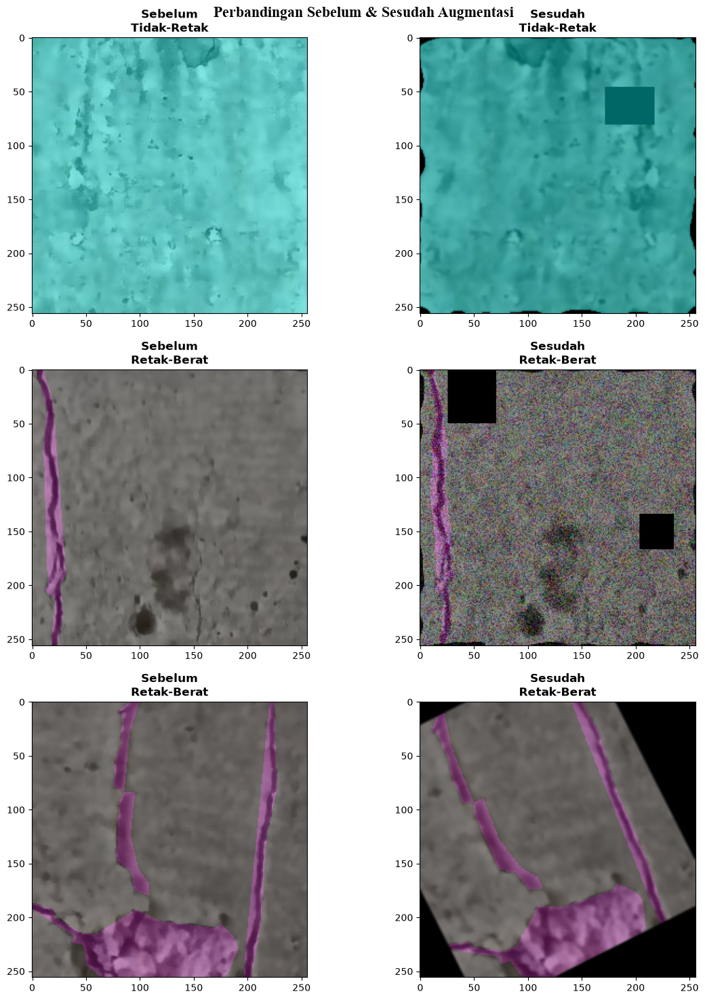


VISUALISASI SELESAI


In [36]:
def visualize_augmentation_results():
    OUTPUT_BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    
    print("\n" + "="*60)
    print("VISUALISASI HASIL AUGMENTASI")
    print("="*60)
    
    # Konfigurasi visualisasi
    CLASS_COLORS = {
        1: (128, 0, 128),   # Ungu - Retak-Berat
        2: (255, 0, 0),     # Merah - Retak-Ringan
        3: (0, 255, 255)    # Kuning - Tidak-Retak
    }
    
    CLASS_NAMES = {
        1: "Retak-Berat",
        2: "Retak-Ringan", 
        3: "Tidak-Retak"
    }
    
    # Visualisasi untuk setiap split
    for split in ["train", "valid"]:
        print(f"\nVisualisasi {split.upper()}")
        
        split_dir = os.path.join(OUTPUT_BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            print(f"Folder {split} tidak ditemukan")
            continue
        
        # Ambil sample gambar augmentasi
        augmented_images = glob.glob(os.path.join(split_dir, "*_aug_*.jpg"))
        
        if not augmented_images:
            print(f"Tidak ada gambar augmentasi ditemukan di {split}")
            continue
        
        # Pilih sample acak
        sample_images = random.sample(augmented_images, min(9, len(augmented_images)))
        
        # Buat plot
        fig, axes = plt.subplots(3, 3, figsize=(15, 12))
        fig.suptitle(f'Hasil Augmentasi - {split.upper()}', 
                    fontsize=16, fontweight='bold', y=0.98, fontfamily='Times New Roman')
        
        axes = axes.flatten()
        
        for i, img_path in enumerate(sample_images):
            ax = axes[i]
            
            # Cari file mask yang sesuai
            mask_path = os.path.splitext(img_path)[0] + ".png"
            
            # Load gambar dan mask
            img = cv2.imread(img_path)
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            
            if img is None or mask is None:
                ax.text(0.5, 0.5, 'Gagal Load', ha='center', va='center', 
                       transform=ax.transAxes, fontsize=12)
                ax.axis('on')
                continue
            
            # Konversi BGR ke RGB untuk matplotlib
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            # Buat overlay mask
            overlay = np.zeros_like(img_rgb)
            
            for class_id, color in CLASS_COLORS.items():
                class_mask = (mask == class_id)
                overlay[class_mask] = color
            
            # Gabungkan gambar asli dengan overlay
            alpha = 0.6  # Transparansi overlay
            combined = cv2.addWeighted(img_rgb, 1 - alpha, overlay, alpha, 0)
            
            # Tampilkan hasil dengan nama kelas di atas gambar
            ax.imshow(combined)
            ax.axis('off')
            
            # Tambahkan nama kelas yang ada dalam gambar
            unique_classes = [c for c in np.unique(mask) if c in CLASS_NAMES]
            if unique_classes:
                class_labels = " + ".join([CLASS_NAMES[c] for c in unique_classes])
                ax.set_title(class_labels, fontsize=10, fontweight='bold', pad=5)
        
        # Sembunyikan axes yang tidak terpakai
        for j in range(len(sample_images), len(axes)):
            axes[j].axis('off')
        
        plt.tight_layout()
        plt.subplots_adjust(top=0.93)
        plt.show()
        
        # Tampilkan statistik untuk split ini
        print(f"\nStatistik {split}:")
        print(f"  Total gambar augmentasi: {len(augmented_images)}")
        
        # Hitung distribusi class
        class_counts = {1: 0, 2: 0, 3: 0}
        total_masks = 0
        
        for img_path in augmented_images[:100]:  # Sample 100 gambar untuk statistik
            mask_path = os.path.splitext(img_path)[0] + ".png"
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            
            if mask is not None:
                unique_classes = np.unique(mask)
                for class_id in unique_classes:
                    if class_id in class_counts:
                        class_counts[class_id] += 1
                total_masks += 1
        
        if total_masks > 0:
            print(f"  Distribusi class (dalam {total_masks} sample):")
            for class_id, count in class_counts.items():
                percentage = (count / total_masks) * 100
                print(f"    {CLASS_NAMES[class_id]}: {count} ({percentage:.1f}%)")

def visualize_comparison_before_after():
    """Visualisasi perbandingan sebelum dan sesudah augmentasi"""
    print("\n" + "="*60)
    print("PERBANDINGAN SEBELUM & SESUDAH AUGMENTASI")
    print("="*60)
    
    INPUT_BASE_DIR = "Tanggul/eksperimen/dataset/label_segmentation_mask_with_masks"
    OUTPUT_BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    
    CLASS_COLORS = {
        1: (128, 0, 128),   # Ungu - Retak-Berat
        2: (255, 0, 0),     # Merah - Retak-Ringan  
        3: (0, 255, 255)    # Kuning - Tidak-Retak
    }
    
    CLASS_NAMES = {
        1: "Retak-Berat",
        2: "Retak-Ringan", 
        3: "Tidak-Retak"
    }
    
    # Cari gambar asli dari train
    original_dir = os.path.join(INPUT_BASE_DIR, "train")
    original_images = glob.glob(os.path.join(original_dir, "*.jpg"))
    
    if not original_images:
        print("Tidak ada gambar asli ditemukan untuk perbandingan")
        return
    
    # Pilih sample asli
    sample_originals = random.sample(original_images, min(3, len(original_images)))
    
    # Cari gambar augmentasi yang sesuai
    augmented_dir = os.path.join(OUTPUT_BASE_DIR, "train")
    all_augmented = glob.glob(os.path.join(augmented_dir, "*_aug_*.jpg"))
    
    comparisons = []
    
    for original_path in sample_originals:
        base_name = os.path.splitext(os.path.basename(original_path))[0]
        
        # Cari augmentasi dari gambar yang sama
        matching_augmented = [f for f in all_augmented if base_name in f]
        
        if matching_augmented:
            comparisons.append({
                'original': original_path,
                'augmented': random.choice(matching_augmented)
            })
    
    if not comparisons:
        print("Tidak ditemukan pasangan sebelum-sesudah untuk visualisasi")
        return
    
    # Buat plot perbandingan
    fig, axes = plt.subplots(len(comparisons), 2, figsize=(12, 5 * len(comparisons)))
    
    if len(comparisons) == 1:
        axes = axes.reshape(1, -1)
    
    fig.suptitle('Perbandingan Sebelum & Sesudah Augmentasi', fontsize=16, fontweight='bold', 
                y=0.98, fontfamily='Times New Roman')
    
    for i, comp in enumerate(comparisons):
        # SEBELUM - Gambar asli
        ax_before = axes[i, 0]
        
        img_before = cv2.imread(comp['original'])
        mask_before_path = os.path.splitext(comp['original'])[0] + ".png"
        mask_before = cv2.imread(mask_before_path, cv2.IMREAD_GRAYSCALE)
        
        if img_before is not None and mask_before is not None:
            img_before_rgb = cv2.cvtColor(img_before, cv2.COLOR_BGR2RGB)
            overlay_before = np.zeros_like(img_before_rgb)
            
            for class_id, color in CLASS_COLORS.items():
                class_mask = (mask_before == class_id)
                overlay_before[class_mask] = color
            
            combined_before = cv2.addWeighted(img_before_rgb, 0.6, overlay_before, 0.4, 0)
            ax_before.imshow(combined_before)
            
            # Tambahkan nama kelas untuk gambar sebelum
            unique_classes_before = [c for c in np.unique(mask_before) if c in CLASS_NAMES]
            if unique_classes_before:
                class_labels_before = " + ".join([CLASS_NAMES[c] for c in unique_classes_before])
                ax_before.set_title(f'Sebelum\n{class_labels_before}', fontweight='bold', fontsize=12)
            else:
                ax_before.set_title('Sebelum', fontweight='bold', fontsize=12)
        else:
            ax_before.set_title('Sebelum', fontweight='bold', fontsize=12)
        
        ax_before.axis('on')
        
        # SESUDAH - Gambar augmentasi
        ax_after = axes[i, 1]
        
        img_after = cv2.imread(comp['augmented'])
        mask_after_path = os.path.splitext(comp['augmented'])[0] + ".png"
        mask_after = cv2.imread(mask_after_path, cv2.IMREAD_GRAYSCALE)
        
        if img_after is not None and mask_after is not None:
            img_after_rgb = cv2.cvtColor(img_after, cv2.COLOR_BGR2RGB)
            overlay_after = np.zeros_like(img_after_rgb)
            
            for class_id, color in CLASS_COLORS.items():
                class_mask = (mask_after == class_id)
                overlay_after[class_mask] = color
            
            combined_after = cv2.addWeighted(img_after_rgb, 0.6, overlay_after, 0.4, 0)
            ax_after.imshow(combined_after)
            
            # Tambahkan nama kelas untuk gambar sesudah
            unique_classes_after = [c for c in np.unique(mask_after) if c in CLASS_NAMES]
            if unique_classes_after:
                class_labels_after = " + ".join([CLASS_NAMES[c] for c in unique_classes_after])
                ax_after.set_title(f'Sesudah\n{class_labels_after}', fontweight='bold', fontsize=12)
            else:
                ax_after.set_title('Sesudah', fontweight='bold', fontsize=12)
        else:
            ax_after.set_title('Sesudah', fontweight='bold', fontsize=12)
        
        ax_after.axis('on')
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.95)
    plt.show()

# Jalankan visualisasi setelah augmentasi selesai
print("\n" + "="*60)
print("MEMULAI VISUALISASI HASIL AUGMENTASI")
print("="*60)

# Visualisasi hasil augmentasi
visualize_augmentation_results()

# Visualisasi perbandingan sebelum & sesudah
visualize_comparison_before_after()

print("\n" + "="*60)
print("VISUALISASI SELESAI")
print("="*60)

Ringkasan Final Visualisasi Augmentasi


RINGKASAN FINAL - AUGMENTASI DATASET SEGMENTASI

STATISTIK DATASET:

  TRAIN:
    └── Gambar: 16693 total
        ├── Asli: 0
        ├── Augmentasi: 16693
        ├── Mask: 16693
        └── File JSON: 2

  VALID:
    └── Gambar: 7174 total
        ├── Asli: 0
        ├── Augmentasi: 7174
        ├── Mask: 7174
        └── File JSON: 2

  TEST:
    └── Gambar: 90 total
        ├── Asli: 90
        ├── Augmentasi: 0
        ├── Mask: 90
        └── File JSON: 0

TOTAL: 23957 gambar

VISUALISASI SAMPLE FINAL:


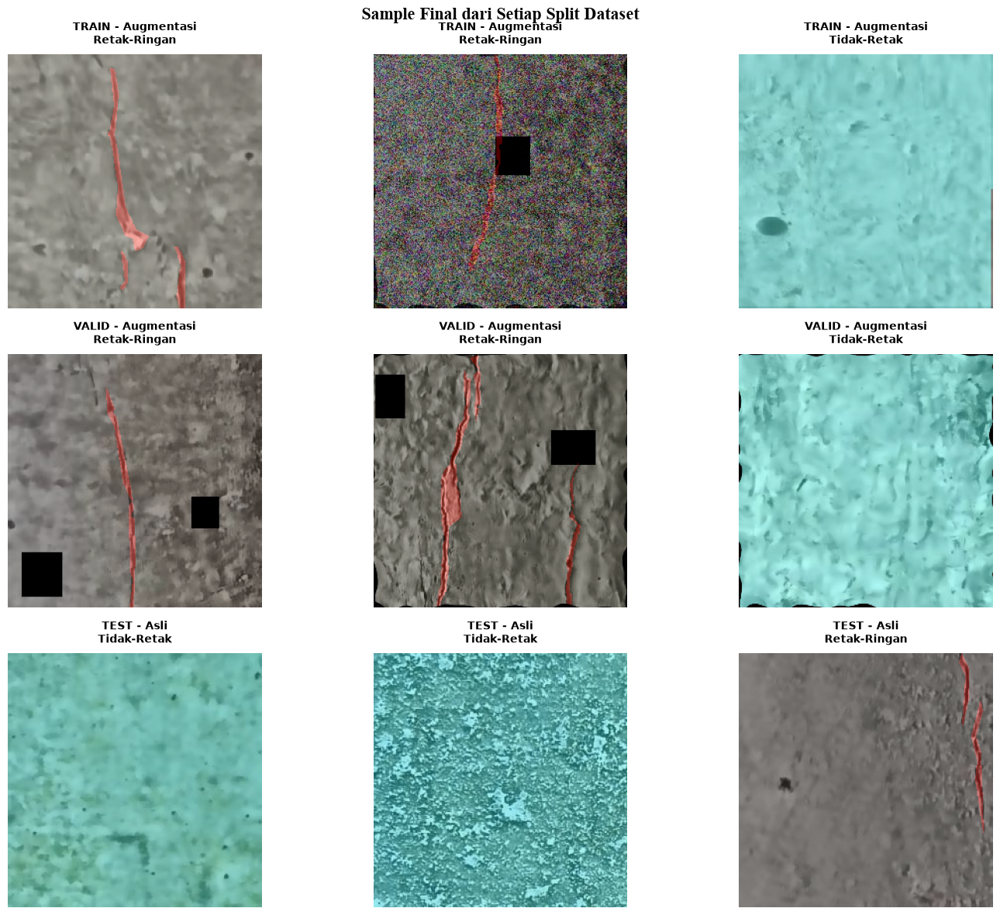


PROSES AUGMENTASI SELESAI!
Dataset tersimpan di: Tanggul/eksperimen/dataset/augmentasi_mask
Siap untuk training model segmentasi

VISUALISASI SELESAI


In [37]:
def final_summary_with_visualization():
    OUTPUT_BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    
    print("\n" + "="*70)
    print("RINGKASAN FINAL - AUGMENTASI DATASET SEGMENTASI")
    print("="*70)
    
    # Hitung statistik final
    total_images = 0
    split_stats = {}
    
    for split in ["train", "valid", "test"]:
        split_dir = os.path.join(OUTPUT_BASE_DIR, split)
        
        if os.path.exists(split_dir):
            images = glob.glob(os.path.join(split_dir, "*.jpg"))
            masks = glob.glob(os.path.join(split_dir, "*.png"))
            json_files = glob.glob(os.path.join(split_dir, "*.json"))
            
            split_stats[split] = {
                'images': len(images),
                'masks': len(masks),
                'json_files': len(json_files),
                'augmented': len([f for f in images if '_aug_' in f]),
                'original': len([f for f in images if '_aug_' not in f])
            }
            total_images += len(images)
    
    # Tampilkan ringkasan
    print("\nSTATISTIK DATASET:")
    for split, stats in split_stats.items():
        print(f"\n  {split.upper()}:")
        print(f"    └── Gambar: {stats['images']} total")
        print(f"        ├── Asli: {stats['original']}")
        print(f"        ├── Augmentasi: {stats['augmented']}")
        print(f"        ├── Mask: {stats['masks']}")
        print(f"        └── File JSON: {stats['json_files']}")
    
    print(f"\nTOTAL: {total_images} gambar")
    
    # Visualisasi sample final dari setiap split
    print(f"\nVISUALISASI SAMPLE FINAL:")
    
    CLASS_COLORS = {
        1: (128, 0, 128),   # Ungu - Retak-Berat
        2: (255, 0, 0),     # Merah - Retak-Ringan
        3: (0, 255, 255)    # Kuning - Tidak-Retak
    }
    
    CLASS_NAMES = {
        1: "Retak-Berat",
        2: "Retak-Ringan", 
        3: "Tidak-Retak"
    }
    
    # Buat visualisasi sample dari setiap split
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    fig.suptitle('Sample Final dari Setiap Split Dataset', fontsize=16, fontweight='bold', y=0.98, fontfamily='Times New Roman')
    
    for i, split in enumerate(["train", "valid", "test"]):
        split_dir = os.path.join(OUTPUT_BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            continue
            
        # Ambil sample dari split ini
        images = glob.glob(os.path.join(split_dir, "*.jpg"))
        if not images:
            continue
            
        sample_images = random.sample(images, min(3, len(images)))
        
        for j, img_path in enumerate(sample_images):
            ax = axes[i, j]
            
            # Load gambar dan mask
            img = cv2.imread(img_path)
            mask_path = os.path.splitext(img_path)[0] + ".png"
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            
            if img is not None and mask is not None:
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                
                # Buat overlay
                overlay = np.zeros_like(img_rgb)
                for class_id, color in CLASS_COLORS.items():
                    class_mask = (mask == class_id)
                    overlay[class_mask] = color
                
                # Gabungkan
                combined = cv2.addWeighted(img_rgb, 0.7, overlay, 0.3, 0)
                ax.imshow(combined)
            
            # Tambahkan nama kelas
            unique_classes = []
            if mask is not None:
                unique_classes = [c for c in np.unique(mask) if c in CLASS_NAMES]
            
            split_type = "Augmentasi" if "_aug_" in os.path.basename(img_path) else "Asli"
            class_labels = " + ".join([CLASS_NAMES[c] for c in unique_classes]) if unique_classes else "Tidak-Retak"
            
            ax.set_title(f'{split.upper()} - {split_type}\n{class_labels}', 
                        fontsize=10, pad=10, fontweight='bold')
            ax.axis('off')
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.93)
    plt.show()
    
    print(f"\nPROSES AUGMENTASI SELESAI!")
    print(f"Dataset tersimpan di: {OUTPUT_BASE_DIR}")
    print(f"Siap untuk training model segmentasi")

# Jalankan ringkasan final
final_summary_with_visualization()

print("\n" + "="*60)
print("VISUALISASI SELESAI")
print("="*60)

Fungsi untuk Membuat COCO JSON dari Data Augmentasi

In [38]:
import json
from tqdm import tqdm

# FUNGSI UNTUK MEMBUAT COCO JSON DARI DATA AUGMENTASI
def create_coco_json_from_augmented_data():
    INPUT_BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    OUTPUT_BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    
    print("\n" + "="*70)
    print("MEMBUAT COCO JSON UNTUK DATA AUGMENTASI")
    print("="*70)
    
    for split in ["train", "valid", "test"]:
        print(f"\nMemproses {split.upper()}")
        
        split_dir = os.path.join(INPUT_BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            print(f"   └── Folder {split} tidak ditemukan")
            continue
        
        # Inisialisasi struktur COCO
        coco_data = {
            "info": {
                "description": f"Augmented Tanggul Segmentation Dataset - {split}",
                "version": "1.0",
                "year": 2025,
                "contributor": "Augmentation Pipeline",
                "date_created": "2025-11-07"
            },
            "licenses": [{
                "id": 1,
                "name": "Academic",
                "url": ""
            }],
            "categories": [
                {"id": 1, "name": "Retak-Berat", "supercategory": "crack"},
                {"id": 2, "name": "Retak-Ringan", "supercategory": "crack"},
                {"id": 3, "name": "Tidak-Retak", "supercategory": "non-crack"}
            ],
            "images": [],
            "annotations": []
        }
        
        # Dapatkan semua file gambar yang diaugmentasi
        image_files = glob.glob(os.path.join(split_dir, "*_aug_*.jpg"))
        
        if not image_files:
            print(f"   └── Tidak ada gambar augmentasi ditemukan di {split}")
            # Coba file gambar biasa (untuk test set)
            image_files = glob.glob(os.path.join(split_dir, "*.jpg"))
        
        print(f"   └── Memproses {len(image_files)} gambar...")
        
        annotation_id = 1
        image_id = 1
        
        for img_path in tqdm(image_files, desc=f"   {split}"):
            filename = os.path.basename(img_path)
            
            # Baca gambar untuk mendapatkan dimensi
            img = cv2.imread(img_path)
            if img is None:
                continue
                
            height, width = img.shape[:2]
            
            # Tambahkan info gambar
            image_info = {
                "id": image_id,
                "file_name": filename,
                "height": height,
                "width": width,
                "license": 1,
                "date_captured": "2025-11-07"
            }
            coco_data["images"].append(image_info)
            
            # Cari file mask yang sesuai
            mask_filename = os.path.splitext(filename)[0] + ".png"
            mask_path = os.path.join(split_dir, mask_filename)
            
            if os.path.exists(mask_path):
                mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                if mask is not None:
                    # Temukan instance untuk setiap class
                    for class_id in [1, 2, 3]:
                        class_mask = (mask == class_id).astype(np.uint8)
                        
                        if np.any(class_mask):
                            # Temukan contours untuk setiap instance terpisah
                            contours, _ = cv2.findContours(
                                class_mask, 
                                cv2.RETR_EXTERNAL, 
                                cv2.CHAIN_APPROX_SIMPLE
                            )
                            
                            for contour in contours:
                                area = cv2.contourArea(contour)
                                if area > 10:  # Filter area kecil
                                    # Buat bounding box
                                    x, y, w, h = cv2.boundingRect(contour)
                                    
                                    # Buat segmentation dari contour
                                    segmentation = contour.flatten().tolist()
                                    
                                    # Buat annotation
                                    annotation = {
                                        "id": annotation_id,
                                        "image_id": image_id,
                                        "category_id": class_id,
                                        "segmentation": [segmentation],
                                        "area": float(area),
                                        "bbox": [x, y, w, h],
                                        "iscrowd": 0
                                    }
                                    coco_data["annotations"].append(annotation)
                                    annotation_id += 1
            
            image_id += 1
        
        # Simpan file COCO JSON
        output_json_path = os.path.join(split_dir, f"_annotations.coco.json")
        with open(output_json_path, 'w', encoding='utf-8') as f:
            json.dump(coco_data, f, indent=2, ensure_ascii=False)
        
        print(f"\nCOCO JSON berhasil dibuat:")
        print(f"      └── File: {os.path.basename(output_json_path)}")
        print(f"      └── Images: {len(coco_data['images'])}")
        print(f"      └── Annotations: {len(coco_data['annotations'])}")
        print(f"      └── Categories: {len(coco_data['categories'])}")
        
        # Hitung statistik per kategori
        category_stats = {1: 0, 2: 0, 3: 0}
        for ann in coco_data['annotations']:
            category_stats[ann['category_id']] += 1
        
        print(f"      └── Distribusi Annotations:")
        print(f"          ├── Retak-Berat: {category_stats[1]}")
        print(f"          ├── Retak-Ringan: {category_stats[2]}")
        print(f"          └── Tidak-Retak: {category_stats[3]}")

Verifikasi Final Structure

In [39]:
def verify_final_structure():
    BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    
    print("\n" + "="*70)
    print("VERIFIKASI STRUKTUR FINAL AUGMENTASI")
    print("="*70)
    
    total_images = 0
    total_annotations = 0
    
    for split in ["train", "valid", "test"]:
        split_dir = os.path.join(BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            print(f"\n{split.upper()}: FOLDER TIDAK ADA")
            continue
            
        print(f"\n{split.upper()}:")
        
        # Hitung file
        jpg_files = glob.glob(os.path.join(split_dir, "*.jpg"))
        png_files = glob.glob(os.path.join(split_dir, "*.png"))
        json_files = glob.glob(os.path.join(split_dir, "*.json"))
        
        print(f"   └── File JPG: {len(jpg_files)}")
        print(f"   └── File PNG: {len(png_files)}")
        print(f"   └── File JSON: {len(json_files)}")
        
        # Cek COCO JSON
        coco_json = [f for f in json_files if 'coco' in f.lower() or 'annotation' in f.lower()]
        if coco_json:
            print(f"   └── COCO JSON: {os.path.basename(coco_json[0])}")
            
            # Baca statistik COCO JSON
            try:
                with open(coco_json[0], 'r') as f:
                    coco_data = json.load(f)
                images_count = len(coco_data.get('images', []))
                annotations_count = len(coco_data.get('annotations', []))
                print(f"      ├── Images: {images_count}")
                print(f"      └── Annotations: {annotations_count}")
                
                total_images += images_count
                total_annotations += annotations_count
                
            except Exception as e:
                print(f"      └── Error membaca COCO JSON: {e}")
        else:
            print(f"   └── COCO JSON: TIDAK DITEMUKAN")
        
        # Cek pasangan gambar-mask
        valid_pairs = 0
        augmented_count = 0
        original_count = 0
        
        for jpg_file in jpg_files:
            base_name = os.path.basename(jpg_file)
            mask_file = os.path.splitext(jpg_file)[0] + ".png"
            
            if os.path.exists(mask_file):
                valid_pairs += 1
                
            if '_aug_' in base_name:
                augmented_count += 1
            else:
                original_count += 1
        
        print(f"   └── Pasangan valid: {valid_pairs}/{len(jpg_files)}")
        print(f"   └── Gambar asli: {original_count}")
        print(f"   └── Gambar augmentasi: {augmented_count}")
    
    # Ringkasan total
    print(f"\nRINGKASAN TOTAL:")
    print(f"   └── Total Images: {total_images}")
    print(f"   └── Total Annotations: {total_annotations}")
    print(f"   └── Rasio Annotations/Image: {total_annotations/total_images:.2f}" if total_images > 0 else "   └── Rasio: N/A")

# JALANKAN CELL 1
print("\n" + "="*70)
print("MEMULAI PROSES PEMBUATAN COCO JSON DAN VERIFIKASI")
print("="*70)

# Jalankan pembuatan COCO JSON
create_coco_json_from_augmented_data()

# Jalankan verifikasi
verify_final_structure()

print("\n" + "="*70)
print("PROSES PEMBUATAN COCO JSON SELESAI!")
print("="*70)


MEMULAI PROSES PEMBUATAN COCO JSON DAN VERIFIKASI

MEMBUAT COCO JSON UNTUK DATA AUGMENTASI

Memproses TRAIN
   └── Memproses 16693 gambar...


   train: 100%|██████████| 16693/16693 [05:23<00:00, 51.58it/s]



COCO JSON berhasil dibuat:
      └── File: _annotations.coco.json
      └── Images: 16693
      └── Annotations: 32690
      └── Categories: 3
      └── Distribusi Annotations:
          ├── Retak-Berat: 13297
          ├── Retak-Ringan: 13893
          └── Tidak-Retak: 5500

Memproses VALID
   └── Memproses 7174 gambar...


   valid: 100%|██████████| 7174/7174 [01:24<00:00, 85.04it/s] 



COCO JSON berhasil dibuat:
      └── File: _annotations.coco.json
      └── Images: 7174
      └── Annotations: 13670
      └── Categories: 3
      └── Distribusi Annotations:
          ├── Retak-Berat: 5285
          ├── Retak-Ringan: 5956
          └── Tidak-Retak: 2429

Memproses TEST
   └── Tidak ada gambar augmentasi ditemukan di test
   └── Memproses 90 gambar...


   test: 100%|██████████| 90/90 [00:01<00:00, 73.11it/s] 



COCO JSON berhasil dibuat:
      └── File: _annotations.coco.json
      └── Images: 90
      └── Annotations: 167
      └── Categories: 3
      └── Distribusi Annotations:
          ├── Retak-Berat: 67
          ├── Retak-Ringan: 70
          └── Tidak-Retak: 30

VERIFIKASI STRUKTUR FINAL AUGMENTASI

TRAIN:
   └── File JPG: 16693
   └── File PNG: 16693
   └── File JSON: 2
   └── COCO JSON: train_annotations.coco.json
      ├── Images: 4200
      └── Annotations: 8184
   └── Pasangan valid: 16693/16693
   └── Gambar asli: 0
   └── Gambar augmentasi: 16693

VALID:
   └── File JPG: 7174
   └── File PNG: 7174
   └── File JSON: 2
   └── COCO JSON: valid_annotations.coco.json
      ├── Images: 1800
      └── Annotations: 3548
   └── Pasangan valid: 7174/7174
   └── Gambar asli: 0
   └── Gambar augmentasi: 7174

TEST:
   └── File JPG: 90
   └── File PNG: 90
   └── File JSON: 1
   └── COCO JSON: _annotations.coco.json
      ├── Images: 90
      └── Annotations: 167
   └── Pasangan valid: 90/9

Visualisasi Hasil COCO JSON


MEMULAI VISUALISASI HASIL COCO JSON

VISUALISASI HASIL COCO JSON - SEGMENTASI

TRAIN:
   └── Memuat 4200 gambar dengan 8184 annotations


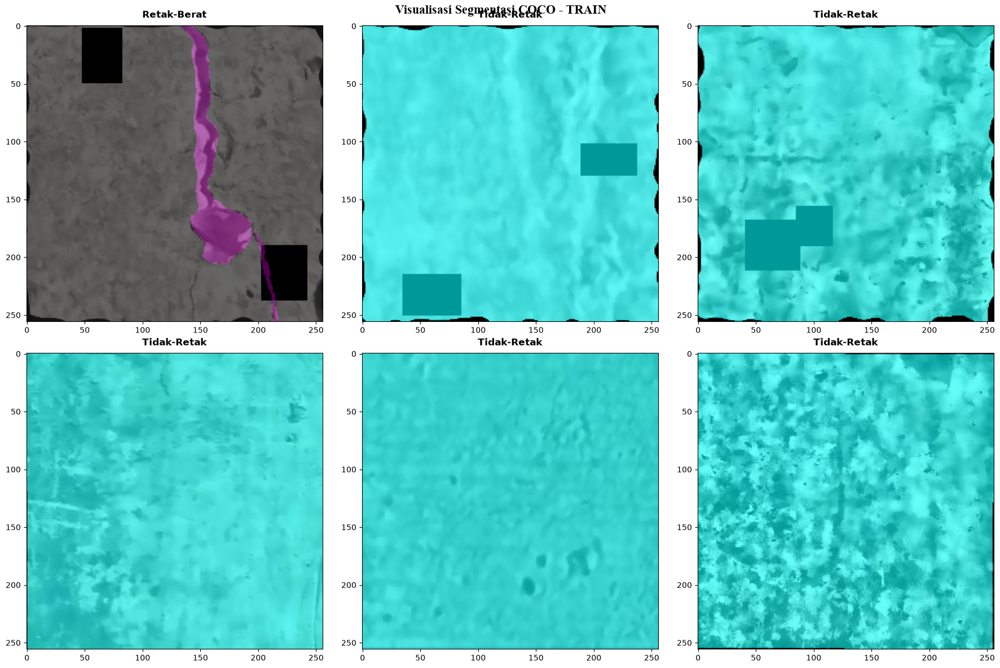

   └── Distribusi Annotations:
       ├── Retak-Berat: 3164
       ├── Retak-Ringan: 3617
       └── Tidak-Retak: 1403
   └── Rata-rata annotations per image: 1.95

VALID:
   └── Memuat 1800 gambar dengan 3548 annotations


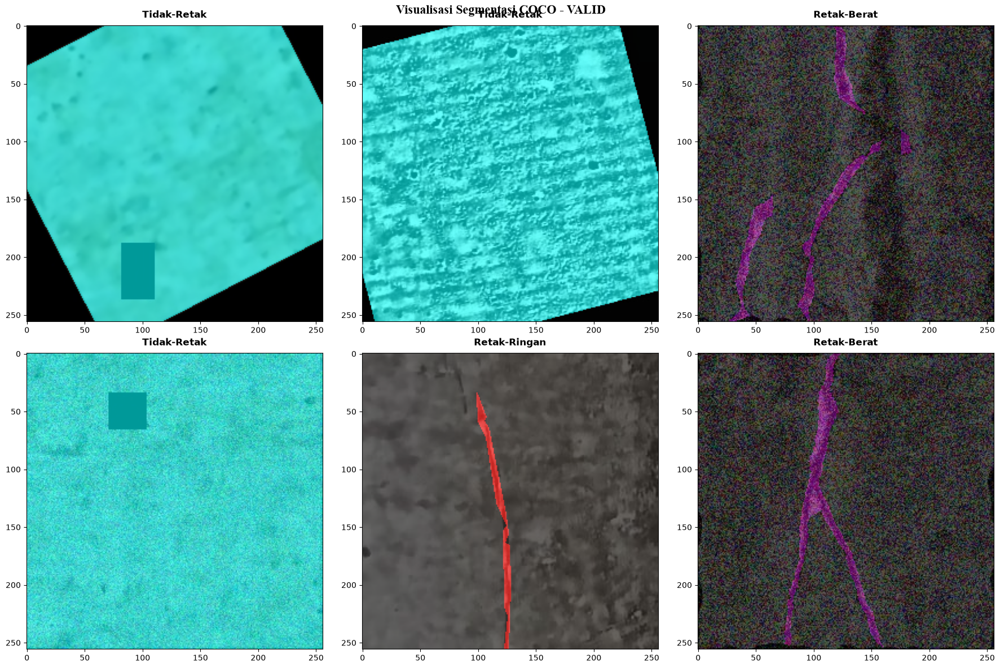

   └── Distribusi Annotations:
       ├── Retak-Berat: 1393
       ├── Retak-Ringan: 1564
       └── Tidak-Retak: 591
   └── Rata-rata annotations per image: 1.97

TEST:
   └── Memuat 90 gambar dengan 167 annotations


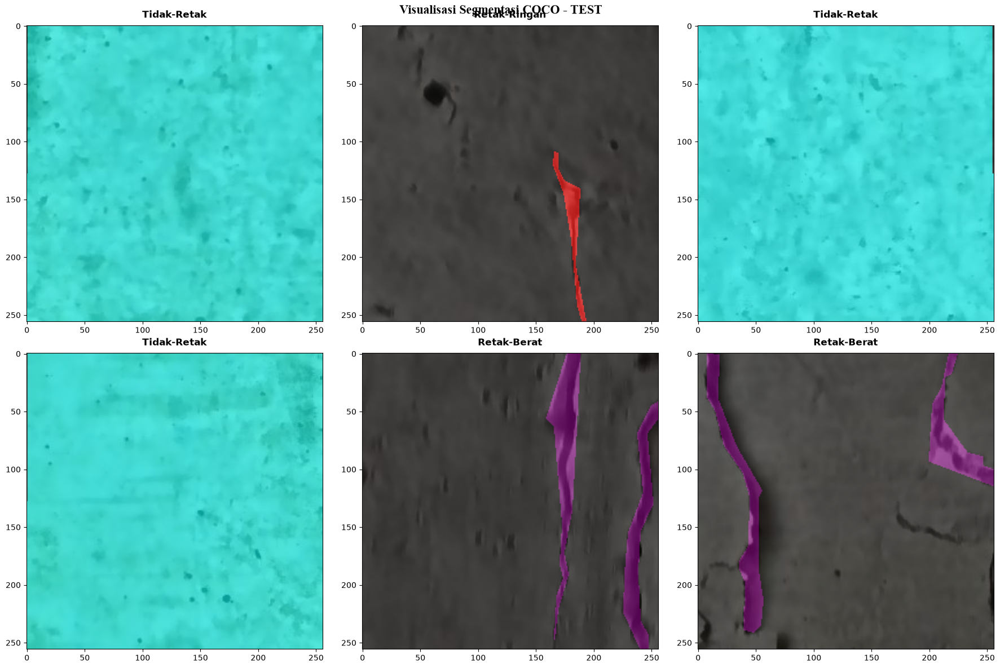

   └── Distribusi Annotations:
       ├── Retak-Berat: 67
       ├── Retak-Ringan: 70
       └── Tidak-Retak: 30
   └── Rata-rata annotations per image: 1.86

VISUALISASI DISTRIBUSI DATA COCO


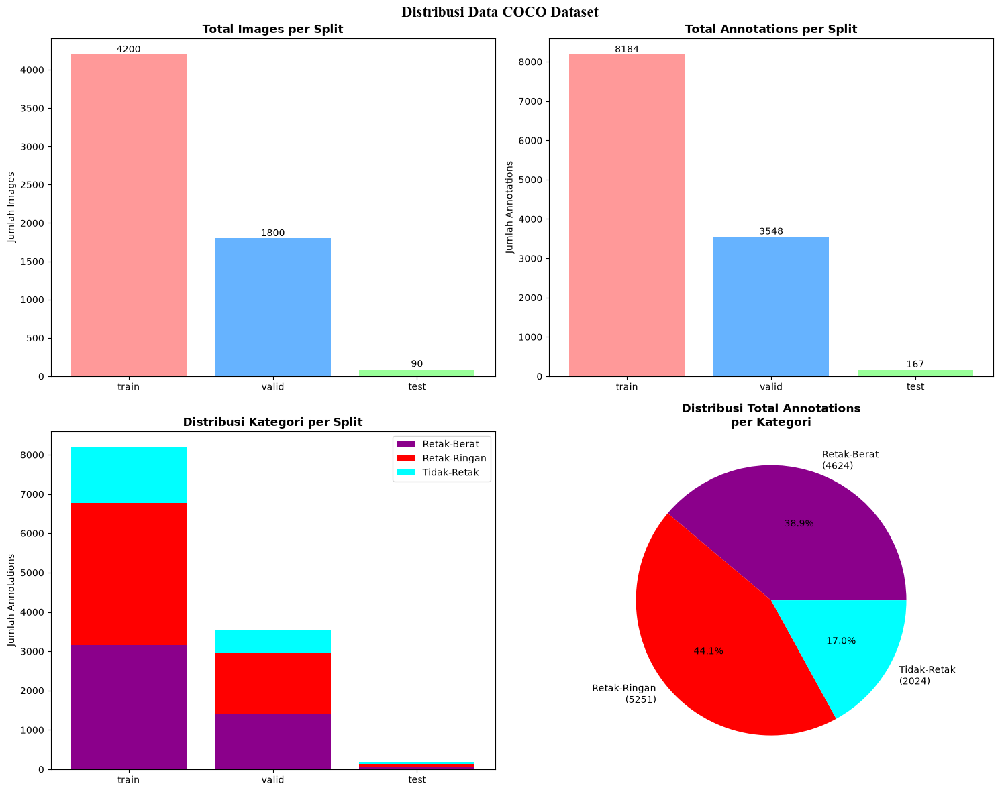


DISTRIBUSI COCO:

  TRAIN:
    └── Images: 4200
    └── Annotations: 8184
    └── Rata-rata per image: 1.95
    └── Distribusi:
        ├── Retak-Berat: 3164 (38.7%)
        ├── Retak-Ringan: 3617 (44.2%)
        ├── Tidak-Retak: 1403 (17.1%)

  VALID:
    └── Images: 1800
    └── Annotations: 3548
    └── Rata-rata per image: 1.97
    └── Distribusi:
        ├── Retak-Berat: 1393 (39.3%)
        ├── Retak-Ringan: 1564 (44.1%)
        ├── Tidak-Retak: 591 (16.7%)

  TEST:
    └── Images: 90
    └── Annotations: 167
    └── Rata-rata per image: 1.86
    └── Distribusi:
        ├── Retak-Berat: 67 (40.1%)
        ├── Retak-Ringan: 70 (41.9%)
        ├── Tidak-Retak: 30 (18.0%)

PROSES VISUALISASI SELESAI!


In [40]:
def visualize_coco_annotations():
    BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    
    print("\n" + "="*70)
    print("VISUALISASI HASIL COCO JSON - SEGMENTASI")
    print("="*70)

    CLASS_COLORS = {
        1: (128, 0, 128),   # Ungu - Retak-Berat
        2: (255, 0, 0),     # Merah - Retak-Ringan
        3: (0, 255, 255)    # Kuning - Tidak-Retak
    }
    
    CLASS_NAMES = {
        1: "Retak-Berat",
        2: "Retak-Ringan", 
        3: "Tidak-Retak"
    }
    
    for split in ["train", "valid", "test"]:
        split_dir = os.path.join(BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            print(f"\n{split.upper()}: FOLDER TIDAK ADA")
            continue
            
        # Cari file COCO JSON
        json_files = glob.glob(os.path.join(split_dir, "*coco*.json"))
        if not json_files:
            print(f"\n{split.upper()}: COCO JSON TIDAK DITEMUKAN")
            continue
            
        coco_json_path = json_files[0]
        
        # Baca COCO JSON
        try:
            with open(coco_json_path, 'r') as f:
                coco_data = json.load(f)
        except Exception as e:
            print(f"\n{split.upper()}: Error membaca COCO JSON - {e}")
            continue
        
        print(f"\n{split.upper()}:")
        print(f"   └── Memuat {len(coco_data['images'])} gambar dengan {len(coco_data['annotations'])} annotations")
        
        # Pilih sample acak untuk divisualisasikan
        sample_images = random.sample(coco_data['images'], min(6, len(coco_data['images'])))
        
        # Buat plot
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle(f'Visualisasi Segmentasi COCO - {split.upper()}', 
                    fontsize=16, fontweight='bold', y=0.98, fontfamily='Times New Roman')
        
        axes = axes.flatten()
        
        for i, image_info in enumerate(sample_images):
            ax = axes[i]
            
            # Load gambar
            img_path = os.path.join(split_dir, image_info['file_name'])
            img = cv2.imread(img_path)
            
            if img is None:
                ax.text(0.5, 0.5, 'Gagal Load\nGambar', ha='center', va='center', 
                       transform=ax.transAxes, fontsize=12)
                ax.axis('off')
                continue
            
            # Konversi BGR ke RGB
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            # Buat mask segmentasi dari annotations
            segmentation_mask = np.zeros(img_rgb.shape, dtype=np.uint8)
            
            # Dapatkan annotations untuk gambar ini
            image_annotations = [ann for ann in coco_data['annotations'] 
                               if ann['image_id'] == image_info['id']]
            
            # Gambar segmentasi pada mask
            for ann in image_annotations:
                class_id = ann['category_id']
                color = CLASS_COLORS.get(class_id, (255, 255, 255))
                
                # Gambar segmentation polygons
                if 'segmentation' in ann and ann['segmentation']:
                    for segmentation in ann['segmentation']:
                        points = np.array(segmentation).reshape(-1, 2).astype(np.int32)
                        cv2.fillPoly(segmentation_mask, [points], color)
            
            # Gabungkan gambar asli dengan mask segmentasi
            alpha = 0.6  # Transparansi overlay
            combined = cv2.addWeighted(img_rgb, 1 - alpha, segmentation_mask, alpha, 0)
            
            # Tampilkan hasil segmentasi
            ax.imshow(combined)
            ax.axis('on')
            
            # Tambahkan nama kelas yang ada dalam gambar
            unique_classes = list(set([ann['category_id'] for ann in image_annotations]))
            if unique_classes:
                class_labels = " + ".join([CLASS_NAMES.get(cid, "Unknown") for cid in unique_classes])
                ax.set_title(class_labels, fontsize=12, fontweight='bold', pad=10)
        
        # Sembunyikan axes yang tidak terpakai
        for j in range(len(sample_images), len(axes)):
            axes[j].axis('on')
        
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        plt.show()
        
        # Tampilkan statistik annotations untuk split ini
        category_stats = {1: 0, 2: 0, 3: 0}
        for ann in coco_data['annotations']:
            category_stats[ann['category_id']] += 1
        
        print(f"   └── Distribusi Annotations:")
        print(f"       ├── Retak-Berat: {category_stats[1]}")
        print(f"       ├── Retak-Ringan: {category_stats[2]}")
        print(f"       └── Tidak-Retak: {category_stats[3]}")
        
        # Statistik tambahan
        annotations_per_image = len(coco_data['annotations']) / len(coco_data['images'])
        print(f"   └── Rata-rata annotations per image: {annotations_per_image:.2f}")

# VISUALISASI DISTRIBUSI DATA COCO
def visualize_coco_distribution():
    BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_mask"
    
    print("\n" + "="*70)
    print("VISUALISASI DISTRIBUSI DATA COCO")
    print("="*70)
    
    CLASS_NAMES = {
        1: "Retak-Berat",
        2: "Retak-Ringan", 
        3: "Tidak-Retak"
    }

    CLASS_COLORS = {
        1: '#8B008B',   # Ungu - Retak-Berat
        2: '#FF0000',   # Merah - Retak-Ringan
        3: '#00FFFF'    # Kuning - Tidak-Retak
    }
    
    # Kumpulkan data dari semua splits
    split_data = {}
    
    for split in ["train", "valid", "test"]:
        split_dir = os.path.join(BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            continue
            
        json_files = glob.glob(os.path.join(split_dir, "*coco*.json"))
        if not json_files:
            continue
            
        try:
            with open(json_files[0], 'r') as f:
                coco_data = json.load(f)
            
            # Hitung statistik
            category_counts = {1: 0, 2: 0, 3: 0}
            for ann in coco_data['annotations']:
                category_counts[ann['category_id']] += 1
            
            split_data[split] = {
                'total_images': len(coco_data['images']),
                'total_annotations': len(coco_data['annotations']),
                'category_counts': category_counts
            }
            
        except Exception as e:
            print(f"Error processing {split}: {e}")
    
    if not split_data:
        print("Tidak ada data COCO yang ditemukan untuk divisualisasikan")
        return
    
    # Buat visualisasi distribusi
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('Distribusi Data COCO Dataset', fontsize=16, fontweight='bold', 
                fontfamily='Times New Roman')
    
    # Total Images per Split
    splits = list(split_data.keys())
    image_counts = [split_data[split]['total_images'] for split in splits]
    
    axes[0, 0].bar(splits, image_counts, color=['#ff9999', '#66b3ff', '#99ff99'])
    axes[0, 0].set_title('Total Images per Split', fontweight='bold')
    axes[0, 0].set_ylabel('Jumlah Images')
    for i, v in enumerate(image_counts):
        axes[0, 0].text(i, v + 0.1, str(v), ha='center', va='bottom')
    
    # Total Annotations per Split
    annotation_counts = [split_data[split]['total_annotations'] for split in splits]
    
    axes[0, 1].bar(splits, annotation_counts, color=['#ff9999', '#66b3ff', '#99ff99'])
    axes[0, 1].set_title('Total Annotations per Split', fontweight='bold')
    axes[0, 1].set_ylabel('Jumlah Annotations')
    for i, v in enumerate(annotation_counts):
        axes[0, 1].text(i, v + 0.1, str(v), ha='center', va='bottom')
    
    # Distribusi Kategori per Split
    category_colors = [CLASS_COLORS[1], CLASS_COLORS[2], CLASS_COLORS[3]]
    category_names = [CLASS_NAMES[1], CLASS_NAMES[2], CLASS_NAMES[3]]
    
    bottom = np.zeros(len(splits))
    for i, class_id in enumerate([1, 2, 3]):
        counts = [split_data[split]['category_counts'][class_id] for split in splits]
        axes[1, 0].bar(splits, counts, bottom=bottom, label=category_names[i], 
                      color=category_colors[i])
        bottom += counts
    
    axes[1, 0].set_title('Distribusi Kategori per Split', fontweight='bold')
    axes[1, 0].set_ylabel('Jumlah Annotations')
    axes[1, 0].legend()
    
    # Pie Chart Distribusi Total Annotations
    total_annotations_all = sum(annotation_counts)
    if total_annotations_all > 0:
        total_by_category = {class_id: 0 for class_id in [1, 2, 3]}
        for split in splits:
            for class_id in [1, 2, 3]:
                total_by_category[class_id] += split_data[split]['category_counts'][class_id]
        
        pie_values = [total_by_category[1], total_by_category[2], total_by_category[3]]
        pie_labels = [f'{CLASS_NAMES[1]}\n({pie_values[0]})', 
                     f'{CLASS_NAMES[2]}\n({pie_values[1]})', 
                     f'{CLASS_NAMES[3]}\n({pie_values[2]})']
        
        axes[1, 1].pie(pie_values, labels=pie_labels, colors=category_colors, autopct='%1.1f%%')
        axes[1, 1].set_title('Distribusi Total Annotations\nper Kategori', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # Tampilkan statistik numerik
    print("\nDISTRIBUSI COCO:")
    for split in splits:
        data = split_data[split]
        print(f"\n  {split.upper()}:")
        print(f"    └── Images: {data['total_images']}")
        print(f"    └── Annotations: {data['total_annotations']}")
        print(f"    └── Rata-rata per image: {data['total_annotations']/data['total_images']:.2f}")
        print(f"    └── Distribusi:")
        for class_id in [1, 2, 3]:
            count = data['category_counts'][class_id]
            percentage = (count / data['total_annotations'] * 100) if data['total_annotations'] > 0 else 0
            print(f"        ├── {CLASS_NAMES[class_id]}: {count} ({percentage:.1f}%)")

print("\n" + "="*70)
print("MEMULAI VISUALISASI HASIL COCO JSON")
print("="*70)

# Jalankan visualisasi COCO
visualize_coco_annotations()
visualize_coco_distribution()

print("\n" + "="*70)
print("PROSES VISUALISASI SELESAI!")
print("="*70)

LABEL BOUNDING BOX ("Tidak Retak, Retak Ringan, Retak Berat")

Hasil Label (Tidak Retak)

In [41]:
import os, json, random, cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

# Pilih file yang ingin ditampilkan
json_choice = "test"  

# Path ke folder JSON dan gambar
BASE_DIR = r"Tanggul/eksperimen/dataset/label_bounding_box"
IMAGE_DIR = os.path.join(BASE_DIR, json_choice)
ANNOT_PATH = os.path.join(IMAGE_DIR, f"{json_choice}_annotations.coco.json")

# Warna bounding box
COLOR_RGB_YELLOW = (255, 255, 0)

# Load font
try:
    font = ImageFont.truetype("times.ttf", 16)
except:
    font = ImageFont.load_default()

Load File COCO dan Filter Gambar “Tidak Retak”

In [42]:
# Load file COCO JSON
with open(ANNOT_PATH, "r") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = coco["categories"]

# Cari ID kategori "Tidak Retak" (bisa "Tidak-Retak" atau "Tidak Retak")
tidak_retak_ids = [c["id"] for c in categories if "tidak" in c["name"].lower()]
if not tidak_retak_ids:
    raise ValueError("Kategori 'Tidak Retak' tidak ditemukan di file anotasi.")

# Filter gambar yang punya anotasi kategori "Tidak Retak"
valid_imgs = []
for img_info in images:
    img_id = img_info["id"]
    annots = [a for a in annotations if a["image_id"] == img_id and a["category_id"] in tidak_retak_ids]
    if annots:
        valid_imgs.append((img_info, annots))

# Pilih gambar acak
sample_imgs = random.sample(valid_imgs, min(9, len(valid_imgs)))

Visualisasi Bounding Box “Tidak Retak”

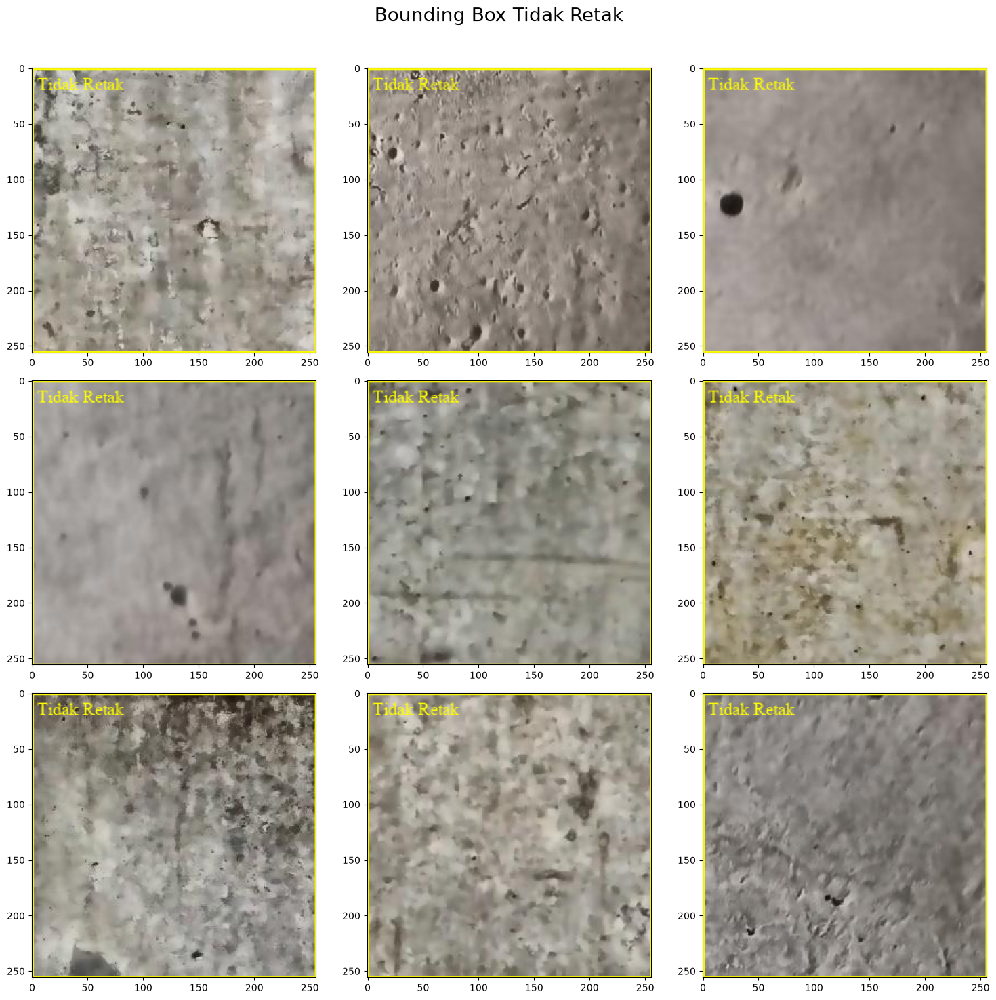

In [43]:
# Tampilkan dengan matplotlib
plt.figure(figsize=(15,15))
for i, (img_info, annots) in enumerate(sample_imgs, 1):
    fname = img_info["file_name"]
    img_path = os.path.join(IMAGE_DIR, fname)
    img = cv2.imread(img_path)
    if img is None:
        continue

    # Resize ke 256x256
    img_resized = cv2.resize(img, (256, 256))

    # Konversi ke RGB untuk PIL
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(img_rgb)
    draw = ImageDraw.Draw(pil_img)

    # Skala bounding box dari ukuran asli ke 256x256
    scale_x = 256 / img_info["width"]
    scale_y = 256 / img_info["height"]

    for ann in annots:
        x, y, w, h = ann["bbox"]
        xmin = int(x * scale_x)
        ymin = int(y * scale_y)
        xmax = int((x + w) * scale_x)
        ymax = int((y + h) * scale_y)

        draw.rectangle([xmin, ymin, xmax, ymax], outline=COLOR_RGB_YELLOW, width=2)
        draw.text((xmin + 5, ymin + 5), "Tidak Retak", font=font, fill=COLOR_RGB_YELLOW)

    # Tampilkan
    plt.subplot(3, 3, i)
    plt.imshow(pil_img)
    plt.axis("on") 

plt.suptitle("Bounding Box Tidak Retak", fontsize=20)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show("on")

Hasil Label (Retak Ringan)

In [44]:
json_choice = "train" 

# Path ke folder JSON dan gambar
BASE_DIR = r"Tanggul/eksperimen/dataset/label_bounding_box"
IMAGE_DIR = os.path.join(BASE_DIR, json_choice)
ANNOT_PATH = os.path.join(IMAGE_DIR, f"{json_choice}_annotations.coco.json")

# Warna bounding box 
COLOR_RGB_RED = (255, 0, 0)

try:
    font = ImageFont.truetype("times.ttf", 16)
except:
    # Jika font 'times.ttf' tidak ditemukan, gunakan font default
    print("Font 'times.ttf' tidak ditemukan")
    font = ImageFont.load_default()

Load JSON dan Filter Gambar “Retak Ringan”

In [45]:
try:
    with open(ANNOT_PATH, "r") as f:
        coco = json.load(f)
    
    images = coco["images"]
    annotations = coco["annotations"]
    categories = coco["categories"]
    print(f"File anotasi '{ANNOT_PATH}' berhasil dimuat.")

    # Filter Gambar "Retak Ringan" 
    retak_ringan_ids = [c["id"] for c in categories if "ringan" in c["name"].lower()]
    
    if not retak_ringan_ids:
        print("ERROR: Kategori 'Retak Ringan' tidak ditemukan di file anotasi")
        valid_imgs = []
    else:
        print(f"ID Kategori 'Retak Ringan' ditemukan: {retak_ringan_ids}")
        
        # Filter gambar yang punya anotasi kategori "Retak Ringan"
        valid_imgs = []
        for img_info in images:
            img_id = img_info["id"]
            # Cek anotasi yang sesuai
            annots = [a for a in annotations if a["image_id"] == img_id and a["category_id"] in retak_ringan_ids]
            if annots:
                valid_imgs.append((img_info, annots))
        
        print(f"Ditemukan {len(valid_imgs)} gambar dengan anotasi 'Retak Ringan'.")

except FileNotFoundError:
    print(f"ERROR: File anotasi tidak ditemukan di {ANNOT_PATH}")
    valid_imgs = [] # Pastikan valid_imgs ada walau error
except Exception as e:
    print(f"Terjadi error saat membaca file JSON: {e}")
    valid_imgs = [] # Pastikan valid_imgs ada walau error

File anotasi 'Tanggul/eksperimen/dataset/label_bounding_box\train\train_annotations.coco.json' berhasil dimuat.
ID Kategori 'Retak Ringan' ditemukan: [2]
Ditemukan 140 gambar dengan anotasi 'Retak Ringan'.


Visualisasi Bounding Box “Retak Ringan”

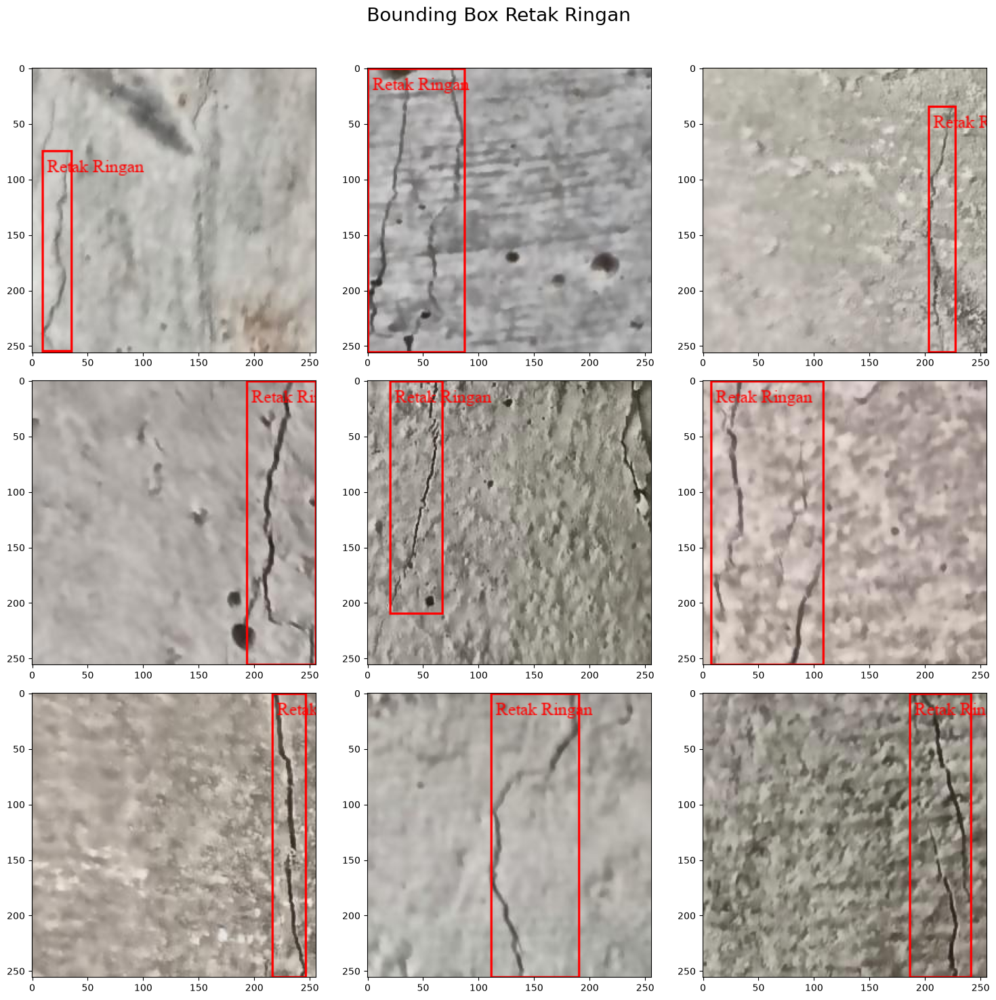

In [46]:
if 'valid_imgs' in locals() and valid_imgs:
    # Pilih gambar acak
    sample_imgs = random.sample(valid_imgs, min(9, len(valid_imgs)))

    # Tampilkan dengan matplotlib
    plt.figure(figsize=(15,15))
    
    for i, (img_info, annots) in enumerate(sample_imgs, 1):
        fname = img_info["file_name"]
        img_path = os.path.join(IMAGE_DIR, fname)
        
        # Baca gambar menggunakan OpenCV
        img = cv2.imread(img_path)
        if img is None:
            print(f"Gagal membaca gambar: {img_path}")
            continue

        img_resized = cv2.resize(img, (256, 256))

        # Konversi ke RGB (karena cv2 BGR, PIL/Matplotlib RGB)
        img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(img_rgb)
        draw = ImageDraw.Draw(pil_img)

        # Hitung skala bounding box dari ukuran asli ke 256x256
        scale_x = 256 / img_info["width"]
        scale_y = 256 / img_info["height"]

        for ann in annots:
            x, y, w, h = ann["bbox"]
            # Terapkan skala ke koordinat bbox
            xmin = int(x * scale_x)
            ymin = int(y * scale_y)
            xmax = int((x + w) * scale_x)
            ymax = int((y + h) * scale_y)

            # Gambar persegi panjang (bounding box) dan label
            draw.rectangle([xmin, ymin, xmax, ymax], outline=COLOR_RGB_RED, width=2)
            draw.text((xmin + 5, ymin + 5), "Retak Ringan", font=font, fill=COLOR_RGB_RED)

        # Tampilkan di subplot
        plt.subplot(3, 3, i)
        plt.imshow(pil_img)
        plt.axis("on") 

    plt.suptitle("Bounding Box Retak Ringan", fontsize=20)
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show("on")
else:
    print("Tidak ada gambar untuk ditampilkan")

Hasil Label (Retak Berat)

In [47]:
json_choice_berat = "valid" 

# Path ke folder JSON dan gambar
BASE_DIR_BERAT = r"Tanggul/eksperimen/dataset/label_bounding_box"
IMAGE_DIR_BERAT = os.path.join(BASE_DIR_BERAT, json_choice_berat)
ANNOT_PATH_BERAT = os.path.join(IMAGE_DIR_BERAT, f"{json_choice_berat}_annotations.coco.json")

COLOR_RGB_PURPLE = (128, 0, 128)

Load JSON dan Filter Gambar “Retak Berat”

In [48]:
try:
    with open(ANNOT_PATH_BERAT, "r") as f:
        coco_berat = json.load(f)
    
    images_berat = coco_berat["images"]
    annotations_berat = coco_berat["annotations"]
    categories_berat = coco_berat["categories"]
    print(f"File anotasi '{ANNOT_PATH_BERAT}' berhasil dimuat.")

    # Filter Gambar "Retak Berat"
    retak_berat_ids = [c["id"] for c in categories_berat if "berat" in c["name"].lower()]
    
    if not retak_berat_ids:
        print("ERROR: Kategori 'Retak Berat' tidak ditemukan di file anotasi.")
        valid_imgs_berat = [] 
    else:
        print(f"ID Kategori 'Retak Berat' ditemukan: {retak_berat_ids}")
        
        # Filter gambar yang punya anotasi kategori "Retak Berat"
        valid_imgs_berat = []
        for img_info in images_berat:
            img_id = img_info["id"]
            # Cek anotasi yang sesuai
            annots = [a for a in annotations_berat if a["image_id"] == img_id and a["category_id"] in retak_berat_ids]
            if annots:
                valid_imgs_berat.append((img_info, annots))
        
        print(f"Ditemukan {len(valid_imgs_berat)} gambar dengan anotasi 'Retak Berat")

except FileNotFoundError:
    print(f"ERROR: File anotasi tidak ditemukan di {ANNOT_PATH_BERAT}")
    valid_imgs_berat = []
except Exception as e:
    print(f"Terjadi error saat membaca file JSON: {e}")
    valid_imgs_berat = [] 

File anotasi 'Tanggul/eksperimen/dataset/label_bounding_box\valid\valid_annotations.coco.json' berhasil dimuat.
ID Kategori 'Retak Berat' ditemukan: [0, 1]
Ditemukan 28 gambar dengan anotasi 'Retak Berat


Visualisasi Bounding Box “Retak Berat”

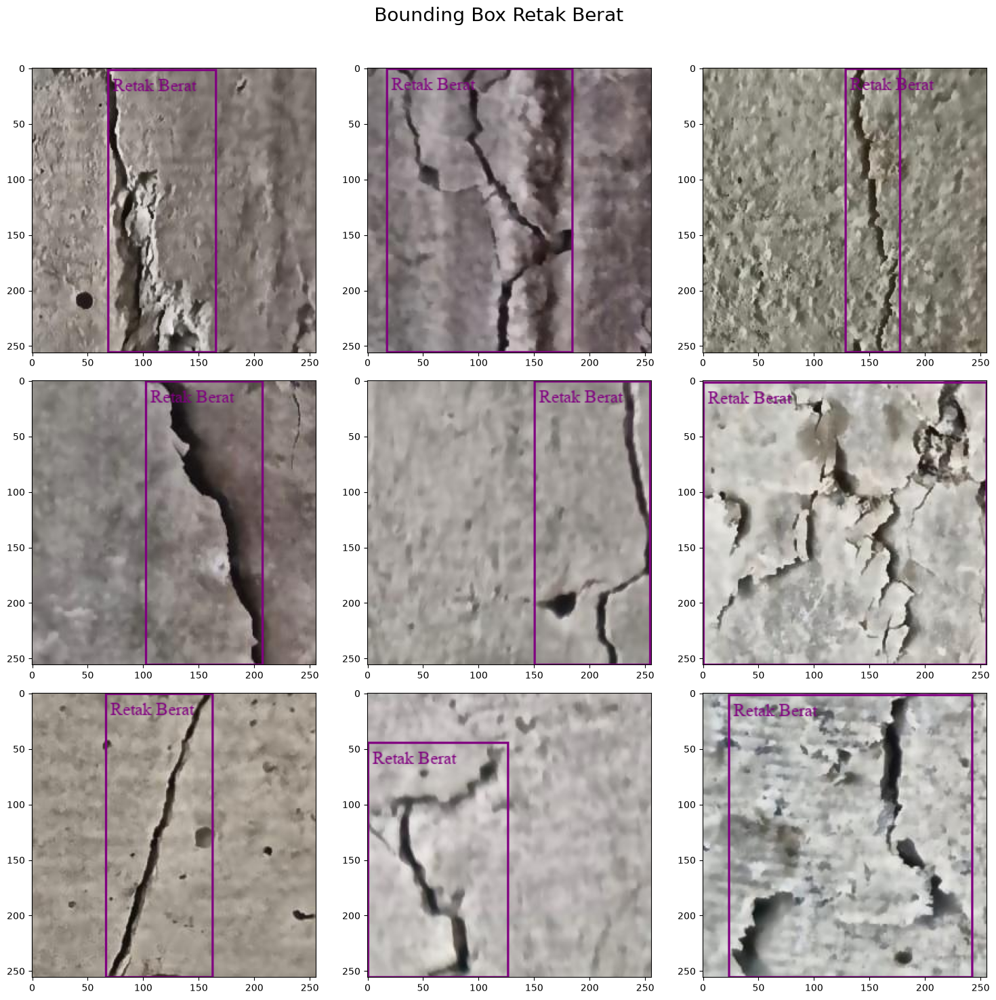

In [49]:
if 'valid_imgs_berat' in locals() and valid_imgs_berat:
    # Pilih gambar acak
    sample_imgs_berat = random.sample(valid_imgs_berat, min(9, len(valid_imgs_berat)))

    # Tampilkan dengan matplotlib
    plt.figure(figsize=(15,15))
    
    for i, (img_info, annots) in enumerate(sample_imgs_berat, 1):
        fname = img_info["file_name"]
        img_path = os.path.join(IMAGE_DIR_BERAT, fname)
        
        img = cv2.imread(img_path)
        if img is None:
            print(f"Gagal membaca gambar: {img_path}")
            continue

        img_resized = cv2.resize(img, (256, 256))
        img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(img_rgb)
        draw = ImageDraw.Draw(pil_img)

        scale_x = 256 / img_info["width"]
        scale_y = 256 / img_info["height"]

        for ann in annots:
            x, y, w, h = ann["bbox"]
            xmin = int(x * scale_x)
            ymin = int(y * scale_y)
            xmax = int((x + w) * scale_x)
            ymax = int((y + h) * scale_y)

            draw.rectangle([xmin, ymin, xmax, ymax], outline=COLOR_RGB_PURPLE, width=2)
            draw.text((xmin + 5, ymin + 5), "Retak Berat", font=font, fill=COLOR_RGB_PURPLE)
           

        # Tampilkan di subplot
        plt.subplot(3, 3, i)
        plt.imshow(pil_img)
        plt.axis("on") 

    plt.suptitle("Bounding Box Retak Berat", fontsize=20)
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show("on")
else:
    print("Tidak ada gambar untuk ditampilkan")

Split Dataset Bounding bbox

In [50]:
base_path_bbox = "Tanggul/eksperimen/dataset/label_bounding_box"
splits_bbox = ["train", "valid", "test"]
total_bbox = 0

for split in splits_bbox:
    # Tentukan path ke file anotasi COCO
    annot_file = os.path.join(base_path_bbox, split, f"{split}_annotations.coco.json")
    
    try:
        # Buka dan baca file JSON
        with open(annot_file, 'r') as f:
            coco_data = json.load(f)
        
        # Dapatkan daftar 'images' dari data COCO
        images_list = coco_data.get("images", [])
        
        # Hitung jumlah gambar
        count = len(images_list)
        total_bbox += count
        
        print(f"Memuat {count} gambar dari split '{split}'")
        
    except FileNotFoundError:
        print(f"INFO: File anotasi tidak ditemukan untuk split '{split}' di: {annot_file}")
    except Exception as e:
        print(f"ERROR: Gagal membaca file JSON untuk split '{split}': {e}")

print(f"Total gambar (BBox): {total_bbox}")

Memuat 420 gambar dari split 'train'
Memuat 90 gambar dari split 'valid'
Memuat 90 gambar dari split 'test'
Total gambar (BBox): 600


Augmentasi_Bounding_Bbox

Import dan Konfigurasi

In [51]:
import os
import shutil
import json
import random
import cv2
import albumentations as A
import numpy as np
from tqdm import tqdm
from sklearn.model_selection import train_test_split

INPUT_BASE_DIR = "Tanggul/eksperimen/dataset/label_bounding_box"
OUTPUT_BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_bbox"

# KONFIGURASI
SPLITS_TO_AUGMENT = ["train", "valid"]
SPLITS_TO_COPY = ["test"]
TARGET_COUNT = 3000  # Target untuk train dan valid
TEST_SIZE = 0.3  # 70/30 split

# Buat folder output utama
os.makedirs(OUTPUT_BASE_DIR, exist_ok=True)
print(f"Input base: {INPUT_BASE_DIR}")
print(f"Output base: {OUTPUT_BASE_DIR}")
print(f"KONFIGURASI: '{' dan '.join(SPLITS_TO_AUGMENT)}' akan diaugmentasi menjadi {TARGET_COUNT} gambar.")
print(f"KONFIGURASI: Split 70/30 akan diterapkan setelah augmentasi")
print(f"KONFIGURASI: '{SPLITS_TO_COPY[0]}' akan disalin (clean).")

Input base: Tanggul/eksperimen/dataset/label_bounding_box
Output base: Tanggul/eksperimen/dataset/augmentasi_bbox
KONFIGURASI: 'train dan valid' akan diaugmentasi menjadi 3000 gambar.
KONFIGURASI: Split 70/30 akan diterapkan setelah augmentasi
KONFIGURASI: 'test' akan disalin (clean).


Definisi Pipeline Augmentasi

In [52]:
# Definisikan pipeline augmentasi SOTA
sota_pipeline = A.Compose([
    # Geometri Dasar
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    
    # Geometri Lebih Kuat (Rotasi, Skala, Geser)
    A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.1, rotate_limit=45, 
                       p=0.8, border_mode=cv2.BORDER_CONSTANT, value=0),

    # Fokus pada Kontras & Kejelasan Retakan
    A.OneOf([
        A.CLAHE(clip_limit=4.0, p=0.7),
        A.RandomGamma(p=0.7),
        A.RandomBrightnessContrast(p=0.7),
    ], p=0.9),

    # Efek "Noise" & Blur (Robustness)
    A.OneOf([
        A.GaussNoise(p=0.5),
        A.Blur(blur_limit=3, p=0.5),
        A.MotionBlur(blur_limit=3, p=0.5),
    ], p=0.5),

    # Simulasi Outdoor
    A.OneOf([
        A.RandomSunFlare(p=0.3),
        A.RandomShadow(p=0.3),
    ], p=0.5),
    
    # Teknik "Occlusion" (Cutout)
    A.CoarseDropout(max_holes=10, max_height=40, max_width=40, 
                    min_holes=5, min_height=20, min_width=20, 
                    fill_value=0, p=0.7)

], bbox_params=A.BboxParams(format='coco', label_fields=['category_ids'], min_visibility=0.2))

print("Pipeline augmentasi 'SOTA' berhasil didefinisikan")

Pipeline augmentasi 'SOTA' berhasil didefinisikan


C:\Users\Dwi-Metcha\AppData\Roaming\Python\Python314\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
C:\Users\Dwi-Metcha\AppData\Local\Temp\ipykernel_9268\1091998072.py:8: UserWarning: Argument(s) 'value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.1, rotate_limit=45,
C:\Users\Dwi-Metcha\AppData\Local\Temp\ipykernel_9268\1091998072.py:32: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=10, max_height=40, max_width=40,


Fungsi Augmentasi Split

In [53]:
def augment_split(input_dir, output_dir, split_name, target_count):
    """Augmentasi satu split dan return data yang sudah diaugmentasi"""
    
    # Path file JSON
    input_json_path = os.path.join(input_dir, f"{split_name}_annotations.coco.json")
    
    try:
        with open(input_json_path, 'r') as f:
            coco_data = json.load(f)
    except FileNotFoundError:
        print(f"ERROR: File anotasi {input_json_path} tidak ditemukan. Augmentasi '{split_name}' dibatalkan.")
        return None

    # Siapkan struktur COCO JSON untuk data augmentasi
    augmented_data = {
        "info": coco_data.get("info", {}),
        "licenses": coco_data.get("licenses", []),
        "categories": coco_data["categories"], 
        "images": [],
        "annotations": []
    }

    # Ambil data asli
    original_images = coco_data["images"]
    original_annotations = coco_data["annotations"]
           
    ann_map = {}
    for ann in original_annotations:
        img_id = ann["image_id"]
        if img_id not in ann_map:
            ann_map[img_id] = []
        ann_map[img_id].append(ann)

    if not original_images:
        print(f"ERROR: Tidak ada gambar ditemukan di file JSON '{split_name}'.")
        return None

    print(f"Ditemukan {len(original_images)} gambar asli di '{split_name}'. Memulai augmentasi hingga {target_count} gambar")

    # ID baru untuk gambar dan anotasi
    new_img_id = 1
    new_ann_id = 1

    # Loop hingga target tercapai
    pbar = tqdm(total=target_count, desc=f"Augmentasi '{split_name}'")
    
    all_augmented_images = []
    all_augmented_annotations = []
    
    while new_img_id <= target_count:
        
        # Pilih gambar acak dari dataset asli untuk diaugmentasi
        img_info = random.choice(original_images)
        img_id = img_info["id"]
        
        # Load gambar
        img_path = os.path.join(input_dir, img_info["file_name"])
        image = cv2.imread(img_path)
        if image is None:
            continue
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) 
              
        bboxes = []
        category_ids = []
        if img_id in ann_map:
            for ann in ann_map[img_id]:
                bboxes.append(ann["bbox"])
                category_ids.append(ann["category_id"])

        # Terapkan augmentasi
        try:
            transformed = sota_pipeline(image=image, bboxes=bboxes, category_ids=category_ids)
            transformed_image = transformed['image']
            transformed_bboxes = transformed['bboxes']
            transformed_category_ids = transformed['category_ids']
        except Exception as e:
            continue
        
        if not transformed_bboxes and bboxes:
             continue 

        # Simpan gambar baru
        new_filename = f"{os.path.splitext(os.path.basename(img_info['file_name']))[0]}_aug_{new_img_id}.jpg"
        output_img_path = os.path.join(output_dir, new_filename)
        cv2.imwrite(output_img_path, cv2.cvtColor(transformed_image, cv2.COLOR_RGB2BGR))

        # Buat info gambar baru
        new_image_info = {
            "id": new_img_id,
            "file_name": new_filename,
            "width": transformed_image.shape[1],
            "height": transformed_image.shape[0],
            "original_split": split_name  # Simpan info split asal
        }
        all_augmented_images.append(new_image_info)

        # Buat anotasi baru
        for bbox, cat_id in zip(transformed_bboxes, transformed_category_ids):
            new_annotation = {
                "id": new_ann_id,
                "image_id": new_img_id,
                "category_id": cat_id,
                "bbox": list(bbox),
                "area": bbox[2] * bbox[3],
                "iscrowd": 0,
                "segmentation": [] 
            }
            all_augmented_annotations.append(new_annotation)
            new_ann_id += 1
        
        new_img_id += 1
        pbar.update(1)
        
    pbar.close()
    
    # Simpan data augmentasi ke struktur
    augmented_data["images"] = all_augmented_images
    augmented_data["annotations"] = all_augmented_annotations
    
    return augmented_data

Fungsi Split Dataset

In [54]:
def split_dataset(augmented_data, output_base_dir, test_size=0.3):
    """Split dataset menjadi train dan valid dengan rasio 70/30"""
    
    # Ekstrak semua gambar
    all_images = augmented_data["images"]
    all_annotations = augmented_data["annotations"]
    
    if not all_images:
        print("ERROR: Tidak ada data untuk di-split")
        return
    
    # Split images menjadi train dan valid
    train_images, valid_images = train_test_split(
        all_images, test_size=test_size, random_state=42
    )
    
    print(f"Split hasil: Train={len(train_images)}, Valid={len(valid_images)}")
    
    # Buat mapping image_id ke annotations
    ann_map = {}
    for ann in all_annotations:
        img_id = ann["image_id"]
        if img_id not in ann_map:
            ann_map[img_id] = []
        ann_map[img_id].append(ann)
    
    # Siapkan data untuk train dan valid
    train_data = {
        "info": augmented_data["info"],
        "licenses": augmented_data["licenses"],
        "categories": augmented_data["categories"],
        "images": [],
        "annotations": []
    }
    
    valid_data = {
        "info": augmented_data["info"],
        "licenses": augmented_data["licenses"],
        "categories": augmented_data["categories"],
        "images": [],
        "annotations": []
    }
    
    # Process train images
    train_img_id_map = {}
    new_train_img_id = 1
    new_train_ann_id = 1
    
    for img_info in train_images:
        old_img_id = img_info["id"]
        train_img_id_map[old_img_id] = new_train_img_id
        
        # Update image info dengan ID baru
        new_img_info = img_info.copy()
        new_img_info["id"] = new_train_img_id
        train_data["images"].append(new_img_info)
        
        # Copy annotations
        if old_img_id in ann_map:
            for ann in ann_map[old_img_id]:
                new_ann = ann.copy()
                new_ann["id"] = new_train_ann_id
                new_ann["image_id"] = new_train_img_id
                train_data["annotations"].append(new_ann)
                new_train_ann_id += 1
        
        new_train_img_id += 1
    
    # Process valid images
    valid_img_id_map = {}
    new_valid_img_id = 1
    new_valid_ann_id = 1
    
    for img_info in valid_images:
        old_img_id = img_info["id"]
        valid_img_id_map[old_img_id] = new_valid_img_id
        
        # Update image info dengan ID baru
        new_img_info = img_info.copy()
        new_img_info["id"] = new_valid_img_id
        valid_data["images"].append(new_img_info)
        
        # Copy annotations
        if old_img_id in ann_map:
            for ann in ann_map[old_img_id]:
                new_ann = ann.copy()
                new_ann["id"] = new_valid_ann_id
                new_ann["image_id"] = new_valid_img_id
                valid_data["annotations"].append(new_ann)
                new_valid_ann_id += 1
        
        new_valid_img_id += 1
    
    # Buat direktori output
    train_dir = os.path.join(output_base_dir, "train")
    valid_dir = os.path.join(output_base_dir, "valid")
    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(valid_dir, exist_ok=True)
    
    # Pindahkan gambar ke direktori yang sesuai
    for img_info in train_images:
        src_path = os.path.join(output_base_dir, "temp_aug", img_info["file_name"])
        dst_path = os.path.join(train_dir, img_info["file_name"])
        if os.path.exists(src_path):
            shutil.move(src_path, dst_path)
    
    for img_info in valid_images:
        src_path = os.path.join(output_base_dir, "temp_aug", img_info["file_name"])
        dst_path = os.path.join(valid_dir, img_info["file_name"])
        if os.path.exists(src_path):
            shutil.move(src_path, dst_path)
    
    # Simpan file JSON
    train_json_path = os.path.join(train_dir, "train_annotations.coco.json")
    valid_json_path = os.path.join(valid_dir, "valid_annotations.coco.json")
    
    with open(train_json_path, 'w') as f:
        json.dump(train_data, f, indent=4)
    
    with open(valid_json_path, 'w') as f:
        json.dump(valid_data, f, indent=4)
    
    print(f"Data train disimpan di: {train_json_path}")
    print(f"Data valid disimpan di: {valid_json_path}")
    
    return train_data, valid_data

Fungsi Proses Utama

In [55]:
def process_dataset():
    """Proses utama: augmentasi dan split dataset"""
    
    print("Menyalin 'test' (tanpa augmentasi)")
    for split in SPLITS_TO_COPY:
        input_split_dir = os.path.join(INPUT_BASE_DIR, split)
        output_split_dir = os.path.join(OUTPUT_BASE_DIR, split)
        
        if os.path.exists(output_split_dir):
            print(f"Menghapus folder '{split}' lama...")
            shutil.rmtree(output_split_dir) 
            
        if os.path.exists(input_split_dir):
            shutil.copytree(input_split_dir, output_split_dir)
            print(f"Berhasil menyalin folder: {input_split_dir} -> {output_split_dir}")
        else:
            print(f"WARNING: Folder input {input_split_dir} tidak ditemukan.")

    # Buat direktori temporary untuk menyimpan hasil augmentasi sebelum di-split
    temp_aug_dir = os.path.join(OUTPUT_BASE_DIR, "temp_aug")
    os.makedirs(temp_aug_dir, exist_ok=True)
    
    # Gabungkan semua data augmentasi dari train dan valid
    all_augmented_data = None
    
    for split in SPLITS_TO_AUGMENT:
        print(f"\n--- Memulai Augmentasi SOTA untuk '{split.upper()}' ---")
        
        input_dir = os.path.join(INPUT_BASE_DIR, split)
        
        # Augmentasi split
        augmented_data = augment_split(input_dir, temp_aug_dir, split, TARGET_COUNT)
        
        if augmented_data is None:
            continue
            
        # Gabungkan dengan data sebelumnya
        if all_augmented_data is None:
            all_augmented_data = augmented_data
        else:
            # Update IDs untuk menghindari duplikasi
            max_img_id = max(img["id"] for img in all_augmented_data["images"])
            max_ann_id = max(ann["id"] for ann in all_augmented_data["annotations"])
            
            for img in augmented_data["images"]:
                img["id"] += max_img_id
                all_augmented_data["images"].append(img)
            
            for ann in augmented_data["annotations"]:
                ann["id"] += max_ann_id
                ann["image_id"] += max_img_id
                all_augmented_data["annotations"].append(ann)
    
    if all_augmented_data is not None:
        print(f"\nTotal data setelah augmentasi: {len(all_augmented_data['images'])} gambar")
        
        # Split dataset menjadi train dan valid
        print("\nMemulai Split Dataset 70/30")
        train_data, valid_data = split_dataset(all_augmented_data, OUTPUT_BASE_DIR, TEST_SIZE)
        
        # Hapus direktori temporary
        if os.path.exists(temp_aug_dir):
            shutil.rmtree(temp_aug_dir)
    else:
        print("ERROR: Tidak ada data yang berhasil diaugmentasi")

    print("Proses Augmentasi dan Split Selesai")

In [56]:
process_dataset()

Menyalin 'test' (tanpa augmentasi)
Menghapus folder 'test' lama...
Berhasil menyalin folder: Tanggul/eksperimen/dataset/label_bounding_box\test -> Tanggul/eksperimen/dataset/augmentasi_bbox\test

--- Memulai Augmentasi SOTA untuk 'TRAIN' ---
Ditemukan 420 gambar asli di 'train'. Memulai augmentasi hingga 3000 gambar


Augmentasi 'train': 100%|██████████| 3000/3000 [01:49<00:00, 27.44it/s]



--- Memulai Augmentasi SOTA untuk 'VALID' ---
Ditemukan 90 gambar asli di 'valid'. Memulai augmentasi hingga 3000 gambar


Augmentasi 'valid': 100%|██████████| 3000/3000 [01:23<00:00, 35.98it/s]



Total data setelah augmentasi: 6000 gambar

Memulai Split Dataset 70/30
Split hasil: Train=4200, Valid=1800
Data train disimpan di: Tanggul/eksperimen/dataset/augmentasi_bbox\train\train_annotations.coco.json
Data valid disimpan di: Tanggul/eksperimen/dataset/augmentasi_bbox\valid\valid_annotations.coco.json
Proses Augmentasi dan Split Selesai


Hitung Hasil Akhir

In [57]:
print("\nMenghitung Gambar augmentasi_bbox")

base_path_aug = "Tanggul/eksperimen/dataset/augmentasi_bbox"
splits_aug = ["train", "valid", "test"]
total_aug = 0

for split in splits_aug:
    annot_file = os.path.join(base_path_aug, split, f"{split}_annotations.coco.json")
    
    try:
        with open(annot_file, 'r') as f:
            coco_data = json.load(f)
        
        images_list = coco_data.get("images", [])
        count = len(images_list)
        total_aug += count
        # Cetak hasil
        print(f"Memuat {count} gambar dari split '{split}'")
        
    except FileNotFoundError:
        print(f"INFO: File anotasi tidak ditemukan untuk split '{split}' {annot_file}")
    except Exception as e:
        print(f"ERROR: Gagal membaca file JSON untuk split '{split}': {e}")

print(f"Total gambar (Augmentasi BBox): {total_aug}")


Menghitung Gambar augmentasi_bbox
Memuat 4200 gambar dari split 'train'
Memuat 1800 gambar dari split 'valid'
Memuat 90 gambar dari split 'test'
Total gambar (Augmentasi BBox): 6090


 Visualisasi Hasil

Memulai Visualisasi Hasil Augmentasi


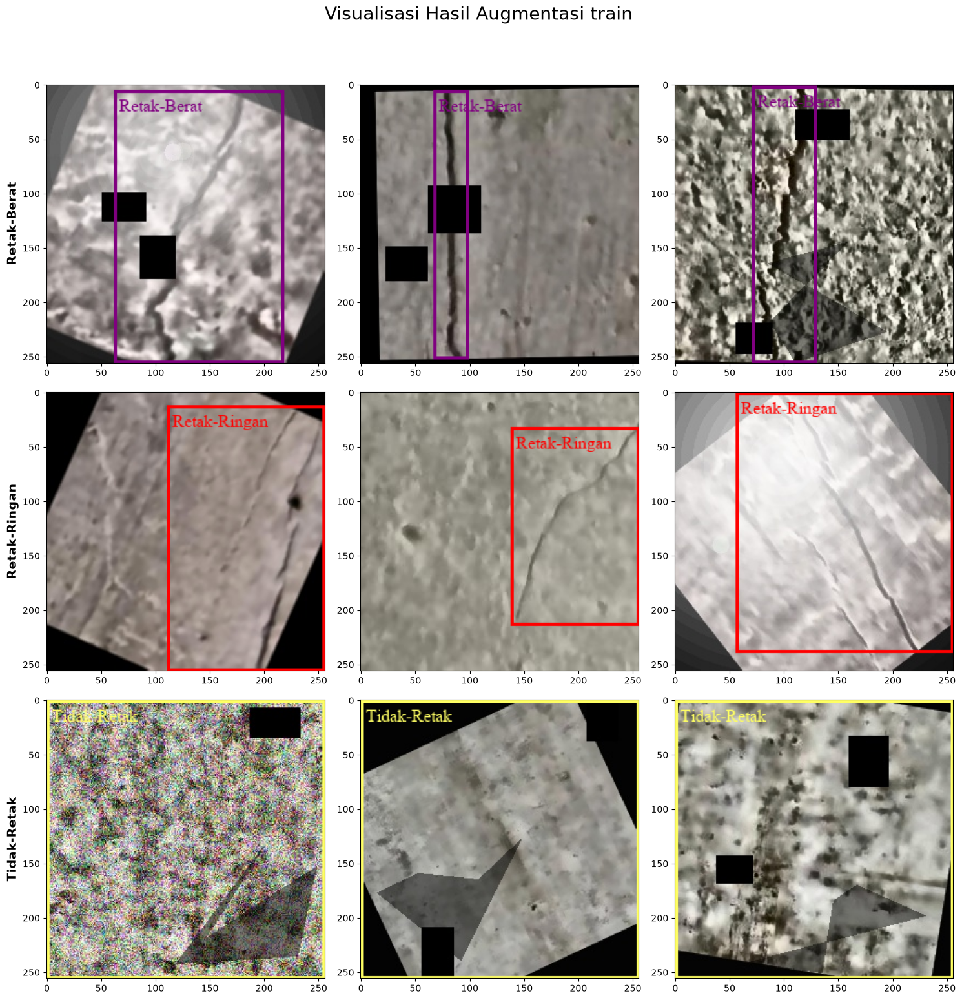

In [58]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

print("Memulai Visualisasi Hasil Augmentasi")

VIS_SPLIT = "train"
VIS_IMG_DIR = os.path.join(OUTPUT_BASE_DIR, VIS_SPLIT)
VIS_ANN_FILE = os.path.join(VIS_IMG_DIR, f"{VIS_SPLIT}_annotations.coco.json")
NUM_SAMPLES = 3

CLASSES_TO_SHOW = ["Retak-Berat", "Retak-Ringan", "Tidak-Retak"]

try:
    font = ImageFont.truetype("times.ttf", 16)
except:
    font = ImageFont.load_default()

# --- Definisi Warna ---
colors = {}
np.random.seed(42)
for cls_name in CLASSES_TO_SHOW:
    colors[cls_name] = tuple(np.random.randint(100, 256, 3))

colors["Retak-Berat"] = (128, 0, 128)   
colors["Retak-Ringan"] = (255, 0, 0)     
colors["Tidak-Retak"] = (255, 255, 100) 

try:
    with open(VIS_ANN_FILE, 'r') as f:
        coco_data = json.load(f)
except FileNotFoundError:
    print(f"ERROR: File anotasi {VIS_ANN_FILE} tidak ditemukan")
    raise SystemExit(f"File {VIS_ANN_FILE} not found.")

categories = coco_data["categories"]
annotations = coco_data["annotations"]
images = coco_data["images"]

cat_id_to_name = {c['id']: c['name'] for c in categories}
cat_name_to_id = {c['name']: c['id'] for c in categories}
img_id_to_info = {img['id']: img for img in images}

img_id_to_anns = {}
for ann in annotations:
    img_id = ann['image_id']
    if img_id not in img_id_to_anns:
        img_id_to_anns[img_id] = []
    img_id_to_anns[img_id].append(ann)

class_to_img_ids = {name: set() for name in CLASSES_TO_SHOW}
for img_id, anns in img_id_to_anns.items():
    for ann in anns:
        class_name = cat_id_to_name.get(ann['category_id'])
        if class_name in class_to_img_ids:
            class_to_img_ids[class_name].add(img_id)

fig, axes = plt.subplots(len(CLASSES_TO_SHOW), NUM_SAMPLES, figsize=(15, 15))

fig.suptitle(f"Visualisasi Hasil Augmentasi {VIS_SPLIT} ", fontsize=20, y=1.03)

for row, class_name in enumerate(CLASSES_TO_SHOW):
    axes[row, 0].set_ylabel(class_name, fontsize=14, fontweight='bold')
    
    img_ids_for_class = list(class_to_img_ids[class_name])
    
    if not img_ids_for_class:
        print(f"Tidak ditemukan gambar untuk kelas '{class_name}' hasil augmentasi")
        axes[row, 1].set_title(f"Tidak ada sampel untuk '{class_name}'")
        continue
    
    # Ambil sampel acak
    sample_img_ids = random.sample(img_ids_for_class, min(NUM_SAMPLES, len(img_ids_for_class)))
    
    for col, img_id in enumerate(sample_img_ids):
        ax = axes[row, col]
        
        # Load gambar
        img_info = img_id_to_info[img_id]
        img_path = os.path.join(VIS_IMG_DIR, img_info['file_name'])
        img = cv2.imread(img_path)
        if img is None:
            ax.set_title("Gagal Load")
            continue
        
        pil_img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        draw = ImageDraw.Draw(pil_img)

        for ann in img_id_to_anns.get(img_id, []):
            x, y, w, h = ann['bbox']
            xmin, ymin, xmax, ymax = int(x), int(y), int(x+w), int(y+h)
            
            label = cat_id_to_name.get(ann['category_id'], "Unknown")
            color = colors.get(label, (255,255,255))
            
            draw.rectangle([xmin, ymin, xmax, ymax], outline=color, width=3)
            draw.text((xmin + 5, ymin + 5), label, font=font, fill=color)
        
        ax.imshow(pil_img)
        ax.axis('on')

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

Visualisasi COCO Annotations (Bounding Box)

In [59]:
def visualize_coco_annotations():
    BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_bbox"
    
    print("\n" + "="*70)
    print("VISUALISASI HASIL COCO JSON - BOUNDING BOX")
    print("="*70)

    CLASS_COLORS = {
        1: (128, 0, 128),   # Ungu - Retak-Berat
        2: (255, 0, 0),     # Merah - Retak-Ringan
        3: (255, 255, 100)  # Kuning - Tidak-Retak
    }
    
    CLASS_NAMES = {
        1: "Retak-Berat",
        2: "Retak-Ringan", 
        3: "Tidak-Retak"
    }
    
    # Setup font Times New Roman
    try:
        # Coba load font Times New Roman
        font_paths = [
            "C:/Windows/Fonts/times.ttf",
            "C:/Windows/Fonts/timesbd.ttf", 
            "C:/Windows/Fonts/timesi.ttf",
            "/usr/share/fonts/truetype/freefont/FreeSerif.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationSerif-Regular.ttf"
        ]
        
        title_font = None
        bbox_font = None
        
        for font_path in font_paths:
            if os.path.exists(font_path):
                title_font = ImageFont.truetype(font_path, 14)
                bbox_font = ImageFont.truetype(font_path, 10)
                break
        
        # Fallback ke font default jika Times New Roman tidak ditemukan
        if title_font is None:
            title_font = ImageFont.load_default()
            bbox_font = ImageFont.load_default()
            print("   └── Font Times New Roman tidak ditemukan, menggunakan font default")
        else:
            print("   └── Font Times New Roman berhasil di-load")
            
    except Exception as e:
        print(f"   └── Error loading font: {e}, menggunakan font default")
        title_font = ImageFont.load_default()
        bbox_font = ImageFont.load_default()
    
    for split in ["train", "valid", "test"]:
        split_dir = os.path.join(BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            print(f"\n{split.upper()}: FOLDER TIDAK ADA")
            continue
            
        # Cari file COCO JSON
        json_files = glob.glob(os.path.join(split_dir, "*coco*.json"))
        if not json_files:
            print(f"\n{split.upper()}: COCO JSON TIDAK DITEMUKAN")
            continue
            
        coco_json_path = json_files[0]
        
        # Baca COCO JSON
        try:
            with open(coco_json_path, 'r') as f:
                coco_data = json.load(f)
        except Exception as e:
            print(f"\n{split.upper()}: Error membaca COCO JSON - {e}")
            continue
        
        print(f"\n{split.upper()}:")
        print(f"   └── Memuat {len(coco_data['images'])} gambar dengan {len(coco_data['annotations'])} annotations")
        
        # Pilih sample acak untuk divisualisasikan
        sample_images = random.sample(coco_data['images'], min(6, len(coco_data['images'])))
        
        # Buat plot
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle(f'Visualisasi Bounding Box COCO - {split.upper()}', 
                    fontsize=16, fontweight='bold', y=0.98, fontfamily='Times New Roman')
        
        axes = axes.flatten()
        
        for i, image_info in enumerate(sample_images):
            ax = axes[i]
            
            # Load gambar
            img_path = os.path.join(split_dir, image_info['file_name'])
            img = cv2.imread(img_path)
            
            if img is None:
                ax.text(0.5, 0.5, 'Gagal Load\nGambar', ha='center', va='center', 
                       transform=ax.transAxes, fontsize=12, fontfamily='Times New Roman')
                ax.axis('off')
                continue
            
            # Konversi BGR ke RGB
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            # Buat gambar PIL untuk drawing
            pil_img = Image.fromarray(img_rgb)
            draw = ImageDraw.Draw(pil_img)
            
            # Dapatkan annotations untuk gambar ini
            image_annotations = [ann for ann in coco_data['annotations'] 
                               if ann['image_id'] == image_info['id']]
            
            # Gambar bounding boxes
            for ann in image_annotations:
                class_id = ann['category_id']
                color = CLASS_COLORS.get(class_id, (255, 255, 255))
                bbox = ann['bbox']
                
                # Convert COCO bbox format [x, y, width, height] to [x1, y1, x2, y2]
                x, y, w, h = bbox
                x1, y1, x2, y2 = int(x), int(y), int(x + w), int(y + h)
                
                # Draw bounding box
                draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
                
                # Draw label background
                label = CLASS_NAMES.get(class_id, "Unknown")
                text_bbox = draw.textbbox((x1, y1), label, font=bbox_font)
                draw.rectangle(text_bbox, fill=color)
                
                # Draw label text dengan font Times New Roman
                draw.text((x1, y1), label, fill=(255, 255, 255), 
                         font=bbox_font)
            
            # Tampilkan hasil
            ax.imshow(pil_img)
            ax.axis('on')
            
            # Hanya tampilkan nama kelas tanpa jumlah bbox
            unique_classes = list(set([ann['category_id'] for ann in image_annotations]))
            if unique_classes:
                class_labels = " + ".join([CLASS_NAMES.get(cid, "Unknown") for cid in unique_classes])
                ax.set_title(class_labels, fontsize=12, fontweight='bold', pad=10, 
                           fontfamily='Times New Roman')
        
        # Sembunyikan axes yang tidak terpakai
        for j in range(len(sample_images), len(axes)):
            axes[j].axis('off')
        
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        plt.show()
        
        # Tampilkan statistik annotations untuk split ini
        category_stats = {1: 0, 2: 0, 3: 0}
        for ann in coco_data['annotations']:
            category_stats[ann['category_id']] += 1
        
        print(f"   └── Distribusi Annotations:")
        print(f"       ├── Retak-Berat: {category_stats[1]}")
        print(f"       ├── Retak-Ringan: {category_stats[2]}")
        print(f"       └── Tidak-Retak: {category_stats[3]}")
        
        # Statistik tambahan
        annotations_per_image = len(coco_data['annotations']) / len(coco_data['images'])
        print(f"   └── Rata-rata annotations per image: {annotations_per_image:.2f}")

Visualisasi Distribusi Data COCO

In [60]:
def visualize_coco_distribution():
    BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_bbox"
    
    print("\n" + "="*70)
    print("VISUALISASI DISTRIBUSI DATA COCO")
    print("="*70)
    
    CLASS_NAMES = {
        1: "Retak-Berat",
        2: "Retak-Ringan", 
        3: "Tidak-Retak"
    }

    CLASS_COLORS = {
        1: '#8B008B',   # Ungu - Retak-Berat
        2: '#FF0000',   # Merah - Retak-Ringan
        3: '#FFD700'    # Kuning - Tidak-Retak
    }
    
    # Setup font Times New Roman untuk plot
    plt.rcParams['font.family'] = 'Times New Roman'
    plt.rcParams['font.size'] = 10
    
    # Kumpulkan data dari semua splits
    split_data = {}
    
    for split in ["train", "valid", "test"]:
        split_dir = os.path.join(BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            continue
            
        json_files = glob.glob(os.path.join(split_dir, "*coco*.json"))
        if not json_files:
            continue
            
        try:
            with open(json_files[0], 'r') as f:
                coco_data = json.load(f)
            
            # Hitung statistik
            category_counts = {1: 0, 2: 0, 3: 0}
            for ann in coco_data['annotations']:
                category_counts[ann['category_id']] += 1
            
            split_data[split] = {
                'total_images': len(coco_data['images']),
                'total_annotations': len(coco_data['annotations']),
                'category_counts': category_counts,
                'images_info': coco_data['images']
            }
            
        except Exception as e:
            print(f"Error processing {split}: {e}")
    
    if not split_data:
        print("Tidak ada data COCO yang ditemukan untuk divisualisasikan")
        return
    
    # Buat visualisasi distribusi
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('Distribusi Data COCO Dataset - Bounding Box', fontsize=16, fontweight='bold')
    
    splits = list(split_data.keys())
    category_colors = [CLASS_COLORS[1], CLASS_COLORS[2], CLASS_COLORS[3]]
    category_names = [CLASS_NAMES[1], CLASS_NAMES[2], CLASS_NAMES[3]]
    
    # 1. Total Images per Split
    image_counts = [split_data[split]['total_images'] for split in splits]
    bars1 = axes[0, 0].bar(splits, image_counts, color=['#ff9999', '#66b3ff', '#99ff99'], alpha=0.8)
    axes[0, 0].set_title('Total Images per Split', fontweight='bold', fontsize=12)
    axes[0, 0].set_ylabel('Jumlah Images')
    axes[0, 0].grid(axis='y', alpha=0.3)
    for bar, count in zip(bars1, image_counts):
        axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
                       str(count), ha='center', va='bottom', fontweight='bold')
    
    # 2. Total Annotations per Split
    annotation_counts = [split_data[split]['total_annotations'] for split in splits]
    bars2 = axes[0, 1].bar(splits, annotation_counts, color=['#ff9999', '#66b3ff', '#99ff99'], alpha=0.8)
    axes[0, 1].set_title('Total Annotations per Split', fontweight='bold', fontsize=12)
    axes[0, 1].set_ylabel('Jumlah Annotations')
    axes[0, 1].grid(axis='y', alpha=0.3)
    for bar, count in zip(bars2, annotation_counts):
        axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
                       str(count), ha='center', va='bottom', fontweight='bold')
    
    # 3. Rata-rata Annotations per Image
    avg_annotations = [split_data[split]['total_annotations'] / split_data[split]['total_images'] 
                      for split in splits]
    bars3 = axes[0, 2].bar(splits, avg_annotations, color=['#ffcc99', '#ccff99', '#99ccff'], alpha=0.8)
    axes[0, 2].set_title('Rata-rata Annotations per Image', fontweight='bold', fontsize=12)
    axes[0, 2].set_ylabel('Rata-rata')
    axes[0, 2].grid(axis='y', alpha=0.3)
    for bar, avg in zip(bars3, avg_annotations):
        axes[0, 2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                       f'{avg:.2f}', ha='center', va='bottom', fontweight='bold')
    
    # 4. Distribusi Kategori per Split (Stacked Bar)
    bottom = np.zeros(len(splits))
    for i, class_id in enumerate([1, 2, 3]):
        counts = [split_data[split]['category_counts'][class_id] for split in splits]
        bars = axes[1, 0].bar(splits, counts, bottom=bottom, label=category_names[i], 
                             color=category_colors[i], alpha=0.8)
        bottom += counts
        
        # Tambahkan label di setiap segment
        for j, (split, count) in enumerate(zip(splits, counts)):
            if count > 0:
                axes[1, 0].text(j, bottom[j] - count/2, str(count), 
                               ha='center', va='center', fontweight='bold', color='white')
    
    axes[1, 0].set_title('Distribusi Kategori per Split', fontweight='bold', fontsize=12)
    axes[1, 0].set_ylabel('Jumlah Annotations')
    axes[1, 0].legend()
    axes[1, 0].grid(axis='y', alpha=0.3)
    
    # 5. Pie Chart Distribusi Total Annotations
    total_annotations_all = sum(annotation_counts)
    if total_annotations_all > 0:
        total_by_category = {class_id: 0 for class_id in [1, 2, 3]}
        for split in splits:
            for class_id in [1, 2, 3]:
                total_by_category[class_id] += split_data[split]['category_counts'][class_id]
        
        pie_values = [total_by_category[1], total_by_category[2], total_by_category[3]]
        pie_labels = [f'{CLASS_NAMES[1]}\n({pie_values[0]})', 
                     f'{CLASS_NAMES[2]}\n({pie_values[1]})', 
                     f'{CLASS_NAMES[3]}\n({pie_values[2]})']
        
        wedges, texts, autotexts = axes[1, 1].pie(pie_values, labels=pie_labels, 
                                                 colors=category_colors, autopct='%1.1f%%',
                                                 startangle=90)
        for autotext in autotexts:
            autotext.set_color('white')
            autotext.set_fontweight('bold')
        axes[1, 1].set_title('Distribusi Total Annotations\nper Kategori', fontweight='bold', fontsize=12)
    
    # 6. Distribusi Ukuran Gambar
    all_widths = []
    all_heights = []
    for split in splits:
        for img_info in split_data[split]['images_info']:
            all_widths.append(img_info['width'])
            all_heights.append(img_info['height'])
    
    if all_widths and all_heights:
        axes[1, 2].scatter(all_widths, all_heights, alpha=0.6, color='purple')
        axes[1, 2].set_xlabel('Width (pixels)')
        axes[1, 2].set_ylabel('Height (pixels)')
        axes[1, 2].set_title('Distribusi Ukuran Gambar', fontweight='bold', fontsize=12)
        axes[1, 2].grid(True, alpha=0.3)
        
        # Tambahkan rata-rata
        avg_width = np.mean(all_widths)
        avg_height = np.mean(all_heights)
        axes[1, 2].axvline(avg_width, color='red', linestyle='--', alpha=0.7, label=f'Avg width: {avg_width:.0f}')
        axes[1, 2].axhline(avg_height, color='blue', linestyle='--', alpha=0.7, label=f'Avg height: {avg_height:.0f}')
        axes[1, 2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # Tampilkan statistik numerik
    print("\nDISTRIBUSI COCO - BOUNDING BOX:")
    print("="*50)
    for split in splits:
        data = split_data[split]
        print(f"\n  {split.upper()}:")
        print(f"    ├── Images: {data['total_images']}")
        print(f"    ├── Annotations: {data['total_annotations']}")
        print(f"    ├── Rata-rata per image: {data['total_annotations']/data['total_images']:.2f}")
        print(f"    └── Distribusi Kategori:")
        total_ann = data['total_annotations']
        for class_id in [1, 2, 3]:
            count = data['category_counts'][class_id]
            percentage = (count / total_ann * 100) if total_ann > 0 else 0
            print(f"        ├── {CLASS_NAMES[class_id]}: {count} ({percentage:.1f}%)")
    
    # Statistik overall
    total_images_all = sum([data['total_images'] for data in split_data.values()])
    total_annotations_all = sum([data['total_annotations'] for data in split_data.values()])
    
    print(f"\n  OVERALL:")
    print(f"    ├── Total Images: {total_images_all}")
    print(f"    ├── Total Annotations: {total_annotations_all}")
    print(f"    └── Rata-rata Global: {total_annotations_all/total_images_all:.2f} annotations/image")

Visualisasi Bounding Box Size Distribution

In [61]:
def visualize_bbox_size_distribution():
    BASE_DIR = "Tanggul/eksperimen/dataset/augmentasi_bbox"
    
    print("\n" + "="*70)
    print("VISUALISASI DISTRIBUSI UKURAN BOUNDING BOX")
    print("="*70)
    
    CLASS_NAMES = {
        1: "Retak-Berat",
        2: "Retak-Ringan", 
        3: "Tidak-Retak"
    }

    CLASS_COLORS = {
        1: '#8B008B',   # Ungu - Retak-Berat
        2: '#FF0000',   # Merah - Retak-Ringan
        3: '#FFD700'    # Kuning - Tidak-Retak
    }
    
    # Setup font Times New Roman untuk plot
    plt.rcParams['font.family'] = 'Times New Roman'
    plt.rcParams['font.size'] = 10
    
    # Kumpulkan data ukuran bbox
    bbox_data = {1: {'widths': [], 'heights': [], 'areas': []},
                2: {'widths': [], 'heights': [], 'areas': []},
                3: {'widths': [], 'heights': [], 'areas': []}}
    
    for split in ["train", "valid"]:
        split_dir = os.path.join(BASE_DIR, split)
        
        if not os.path.exists(split_dir):
            continue
            
        json_files = glob.glob(os.path.join(split_dir, "*coco*.json"))
        if not json_files:
            continue
            
        try:
            with open(json_files[0], 'r') as f:
                coco_data = json.load(f)
            
            # Kumpulkan ukuran bbox
            for ann in coco_data['annotations']:
                class_id = ann['category_id']
                bbox = ann['bbox']
                width, height = bbox[2], bbox[3]
                area = width * height
                
                bbox_data[class_id]['widths'].append(width)
                bbox_data[class_id]['heights'].append(height)
                bbox_data[class_id]['areas'].append(area)
                
        except Exception as e:
            print(f"Error processing {split}: {e}")
    
    # Buat visualisasi
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('Distribusi Ukuran Bounding Box per Kategori', fontsize=16, fontweight='bold')
    
    # 1. Distribusi Lebar BBox
    for class_id in [1, 2, 3]:
        if bbox_data[class_id]['widths']:
            axes[0, 0].hist(bbox_data[class_id]['widths'], bins=50, alpha=0.7, 
                           label=CLASS_NAMES[class_id], color=CLASS_COLORS[class_id])
    axes[0, 0].set_xlabel('Width (pixels)')
    axes[0, 0].set_ylabel('Frequency')
    axes[0, 0].set_title('Distribusi Lebar Bounding Box', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Distribusi Tinggi BBox
    for class_id in [1, 2, 3]:
        if bbox_data[class_id]['heights']:
            axes[0, 1].hist(bbox_data[class_id]['heights'], bins=50, alpha=0.7, 
                           label=CLASS_NAMES[class_id], color=CLASS_COLORS[class_id])
    axes[0, 1].set_xlabel('Height (pixels)')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].set_title('Distribusi Tinggi Bounding Box', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Distribusi Area BBox
    for class_id in [1, 2, 3]:
        if bbox_data[class_id]['areas']:
            axes[1, 0].hist(bbox_data[class_id]['areas'], bins=50, alpha=0.7, 
                           label=CLASS_NAMES[class_id], color=CLASS_COLORS[class_id])
    axes[1, 0].set_xlabel('Area (pixels²)')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('Distribusi Area Bounding Box', fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. Scatter Plot Width vs Height
    for class_id in [1, 2, 3]:
        if bbox_data[class_id]['widths'] and bbox_data[class_id]['heights']:
            axes[1, 1].scatter(bbox_data[class_id]['widths'], bbox_data[class_id]['heights'], 
                              alpha=0.6, label=CLASS_NAMES[class_id], color=CLASS_COLORS[class_id])
    axes[1, 1].set_xlabel('Width (pixels)')
    axes[1, 1].set_ylabel('Height (pixels)')
    axes[1, 1].set_title('Scatter Plot: Width vs Height BBox', fontweight='bold')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Tampilkan statistik ukuran bbox
    print("\nSTATISTIK UKURAN BOUNDING BOX:")
    print("="*50)
    for class_id in [1, 2, 3]:
        if bbox_data[class_id]['widths']:
            widths = bbox_data[class_id]['widths']
            heights = bbox_data[class_id]['heights']
            areas = bbox_data[class_id]['areas']
            
            print(f"\n  {CLASS_NAMES[class_id]}:")
            print(f"    ├── Count: {len(widths)} bbox")
            print(f"    ├── Width:  min={min(widths):.1f}, max={max(widths):.1f}, mean={np.mean(widths):.1f}")
            print(f"    ├── Height: min={min(heights):.1f}, max={max(heights):.1f}, mean={np.mean(heights):.1f}")
            print(f"    └── Area:   min={min(areas):.1f}, max={max(areas):.1f}, mean={np.mean(areas):.1f}")

Jalankan Semua Visualisasi


MEMULAI VISUALISASI HASIL COCO JSON - BOUNDING BOX

VISUALISASI HASIL COCO JSON - BOUNDING BOX
   └── Font Times New Roman berhasil di-load

TRAIN:
   └── Memuat 4200 gambar dengan 4200 annotations


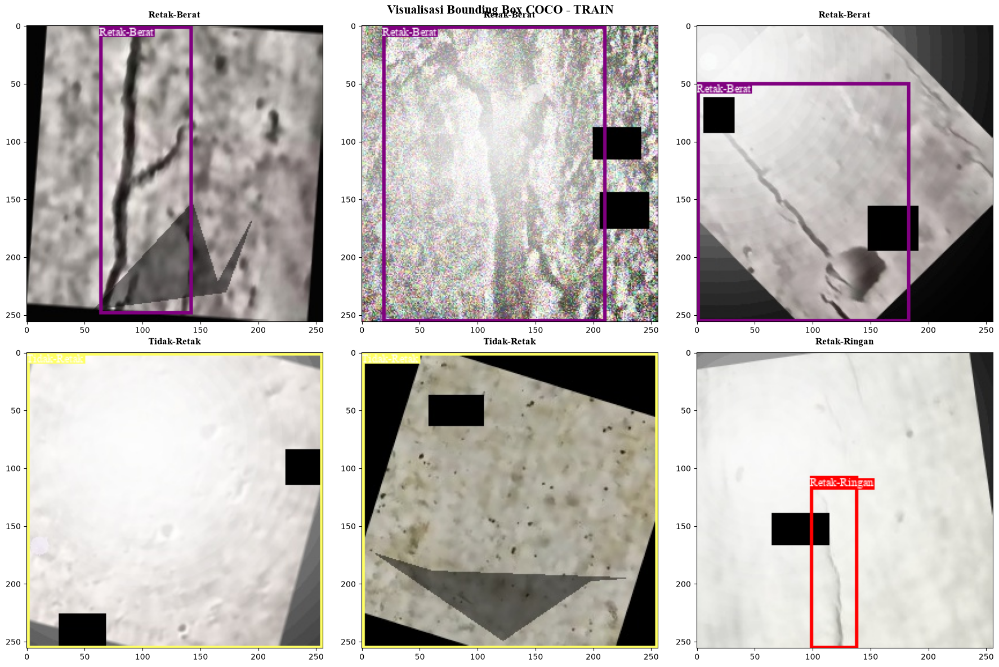

   └── Distribusi Annotations:
       ├── Retak-Berat: 1231
       ├── Retak-Ringan: 1342
       └── Tidak-Retak: 1627
   └── Rata-rata annotations per image: 1.00

VALID:
   └── Memuat 1800 gambar dengan 1800 annotations


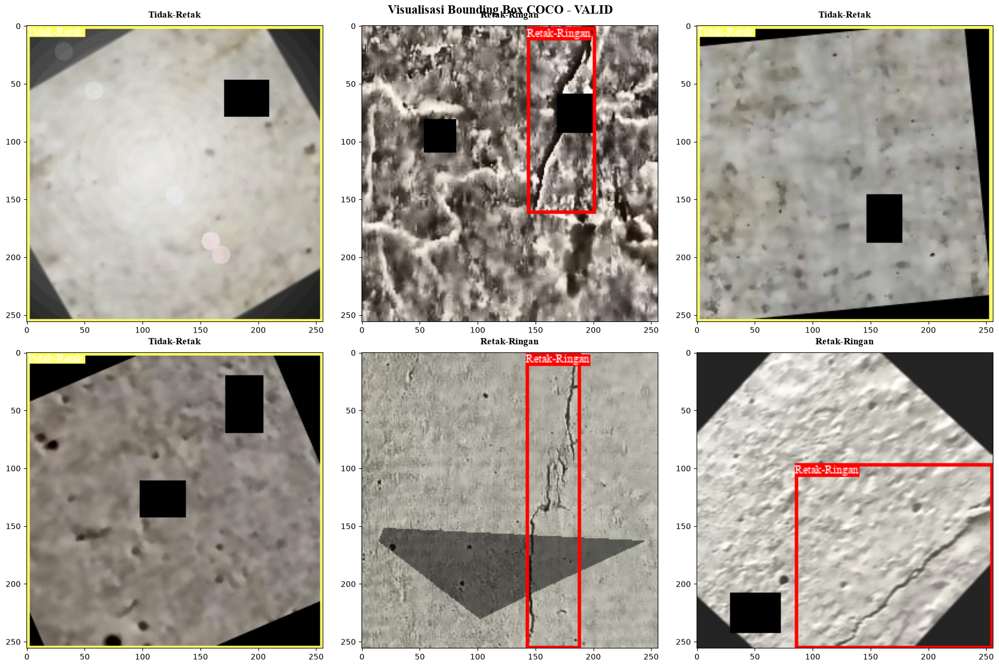

   └── Distribusi Annotations:
       ├── Retak-Berat: 521
       ├── Retak-Ringan: 579
       └── Tidak-Retak: 700
   └── Rata-rata annotations per image: 1.00

TEST:
   └── Memuat 90 gambar dengan 90 annotations


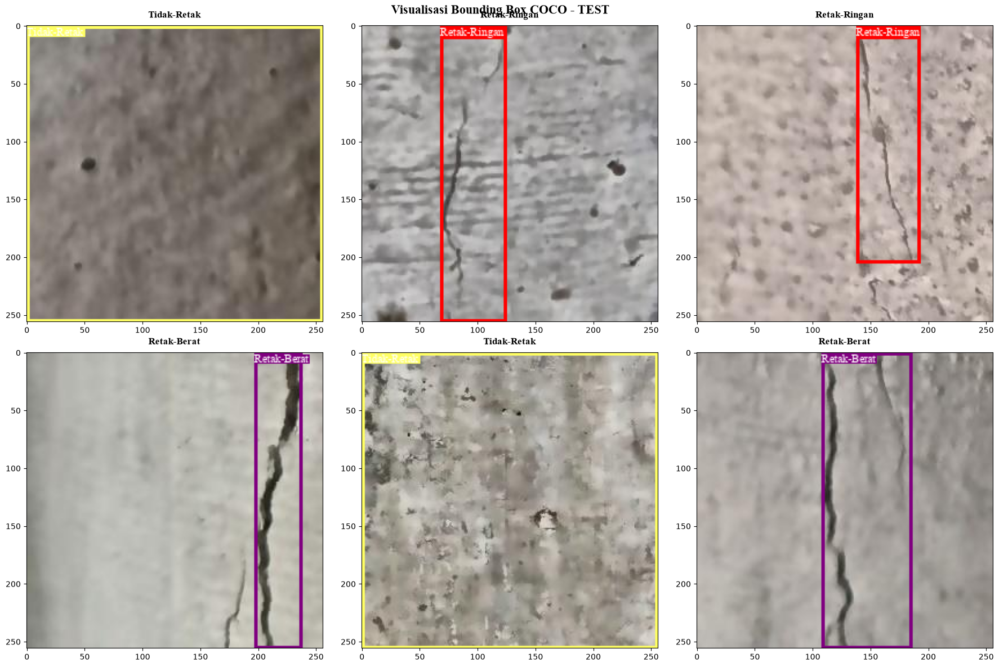

   └── Distribusi Annotations:
       ├── Retak-Berat: 32
       ├── Retak-Ringan: 30
       └── Tidak-Retak: 28
   └── Rata-rata annotations per image: 1.00

VISUALISASI DISTRIBUSI DATA COCO


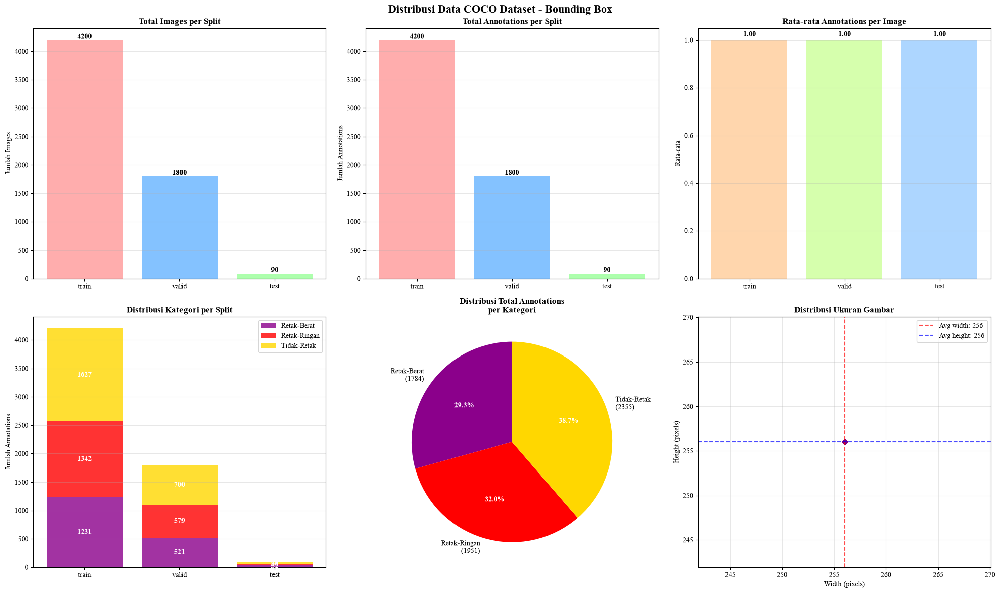


DISTRIBUSI COCO - BOUNDING BOX:

  TRAIN:
    ├── Images: 4200
    ├── Annotations: 4200
    ├── Rata-rata per image: 1.00
    └── Distribusi Kategori:
        ├── Retak-Berat: 1231 (29.3%)
        ├── Retak-Ringan: 1342 (32.0%)
        ├── Tidak-Retak: 1627 (38.7%)

  VALID:
    ├── Images: 1800
    ├── Annotations: 1800
    ├── Rata-rata per image: 1.00
    └── Distribusi Kategori:
        ├── Retak-Berat: 521 (28.9%)
        ├── Retak-Ringan: 579 (32.2%)
        ├── Tidak-Retak: 700 (38.9%)

  TEST:
    ├── Images: 90
    ├── Annotations: 90
    ├── Rata-rata per image: 1.00
    └── Distribusi Kategori:
        ├── Retak-Berat: 32 (35.6%)
        ├── Retak-Ringan: 30 (33.3%)
        ├── Tidak-Retak: 28 (31.1%)

  OVERALL:
    ├── Total Images: 6090
    ├── Total Annotations: 6090
    └── Rata-rata Global: 1.00 annotations/image

VISUALISASI DISTRIBUSI UKURAN BOUNDING BOX


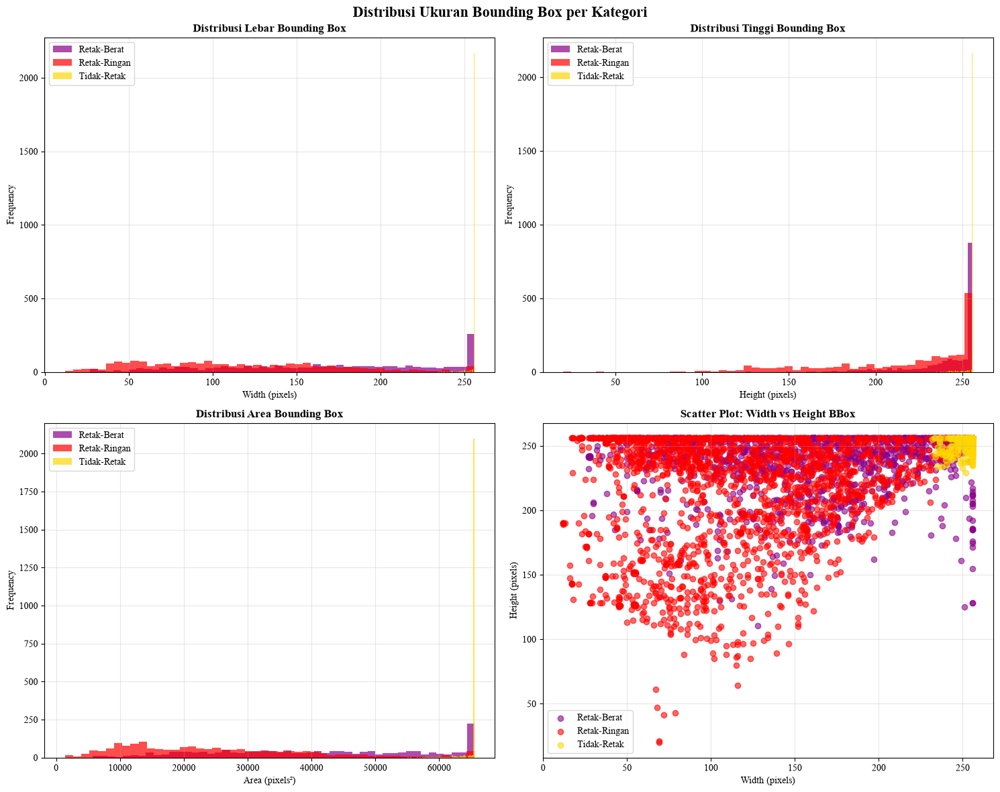


STATISTIK UKURAN BOUNDING BOX:

  Retak-Berat:
    ├── Count: 1752 bbox
    ├── Width:  min=27.0, max=256.0, mean=168.5
    ├── Height: min=110.6, max=256.0, mean=242.1
    └── Area:   min=5684.0, max=65536.0, mean=40968.0

  Retak-Ringan:
    ├── Count: 1921 bbox
    ├── Width:  min=12.0, max=256.0, mean=115.3
    ├── Height: min=20.0, max=256.0, mean=214.6
    └── Area:   min=1380.0, max=65536.0, mean=25126.3

  Tidak-Retak:
    ├── Count: 2327 bbox
    ├── Width:  min=232.0, max=256.0, mean=255.4
    ├── Height: min=229.0, max=256.0, mean=255.4
    └── Area:   min=54990.0, max=65536.0, mean=65240.7

PROSES VISUALISASI SELESAI!


In [62]:
print("\n" + "="*70)
print("MEMULAI VISUALISASI HASIL COCO JSON - BOUNDING BOX")
print("="*70)

# Jalankan visualisasi COCO
visualize_coco_annotations()
visualize_coco_distribution()
visualize_bbox_size_distribution()

print("\n" + "="*70)
print("PROSES VISUALISASI SELESAI!")
print("="*70)